# Intelligent Financial Fraud Detection

**NTU Datathon 2026, Track 2** · Sakthivel and Swarup

Flag fraudulent transactions (1.8% of the data) while raising as few false alarms as possible. This notebook covers the whole workflow: exploration, cleaning, feature engineering, model comparison under repeated cross-validation, threshold selection, and trust checks (overfitting, calibration, bias, usefulness).

Run it from the `notebooks/` folder (or the repository root). It reads `data/train.csv` and `data/test.csv`, saves the final model to `models/model.pkl` and the public-test predictions to `outputs/test_predictions.csv`. Library versions are pinned in `requirements.txt`.


In [1]:
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
MODEL_PATH = ROOT / "models" / "model.pkl"
PREDICTIONS_PATH = ROOT / "outputs" / "test_predictions.csv"

# NumPy on macOS (Accelerate BLAS) emits spurious matmul warnings during scikit-learn fits; results are unaffected.
warnings.filterwarnings("ignore", message=r".* encountered in matmul", category=RuntimeWarning)


# 1. Understanding the Problem



## 1.1 Problem statement

> *How can machine learning identify potentially fraudulent financial transactions while minimising unnecessary disruption to legitimate customers?*

**The task.** We receive a labelled training dataset and an unlabelled test dataset. We train a model to predict, for each Transaction in the test dataset, whether it is Fraud (1) or not (0).

## 1.2 Key terms and metrics

**Terms used throughout**:

| Term | Meaning |
|---|---|
| **Transaction** | One row of the data |
| **Fraud Score** | The model's estimated probability that a Transaction is Fraud |
| **Operating Threshold** | The Fraud Score at or above which a Transaction is Flagged |
| **Flag** | The model's 0/1 decision: 1 = suspected Fraud |
| **Missed Fraud** | A Fraud Transaction that is not Flagged (*false negative*): financial loss |
| **False Alarm** | A legitimate Transaction that is Flagged (*false positive*): disruption to a customer |

**The three scored metrics** all focus on the Fraud class:

| Metric | Question it answers | Depends on the Operating Threshold? |
|---|---|---|
| **Recall** | Of all real Fraud, what share did we Flag? | Yes |
| **F1** | Balance of *precision* (of our Flags, what share were really Fraud?) and Recall | Yes |
| **PR-AUC** | How well does the Fraud Score rank Fraud above legitimate Transactions, across *every* possible threshold? | No |

These definitions imply three facts:

1. A random guess has a PR-AUC equal to the Fraud rate.
2. F1 and Recall depend on the Operating Threshold as well as on the model.
3. Raising Recall by lowering the threshold produces more False Alarms.

## 1.3 Data dictionary

Column meanings come from the dataset description supplied with the training data. The training dataset has all twelve columns; the test dataset has the same columns without `fraud`.

| Column | Meaning |
|---|---|
| `id` | Unique Transaction identifier (not a feature) |
| `transaction_amount` | Monetary value of the Transaction |
| `transaction_hour` | Hour of day, 0-23 |
| `merchant_category` | Kind of merchant (retail, grocery, cash_transfer, ...) |
| `country` | 2-letter country code |
| `transaction_channel` | card_present, ecommerce, mobile_app or bank_transfer |
| `transactions_last_24h` | The Account's number of Transactions in the last 24 hours |
| `spend_last_24h` | The Account's total spend in the last 24 hours |
| `account_age` | Age of the Account in days |
| `new_device` | 1 = Transaction made from a new / untrusted device |
| `transactions_last_1h` | The Account's number of Transactions in the last hour |
| `fraud` | Target: 1 = Fraud, 0 = legitimate |

## 1.4 Submission requirements

From the handbook:

- **Deliverables:** this notebook, the trained model (`model.pkl`), a 1-page technical report and `requirements.txt`.
- **How the organisers score the model:** in a fresh Colab session they copy our feature engineering (`make_features`), load `model.pkl`, call `model.predict()` on the hidden test data, and save the predictions as a CSV.
- **The saved model must therefore:**
  - output 0/1 Flags directly;
  - contain only standard library objects, so it loads in their environment.
- **The notebook must run top to bottom in a clean Colab environment.** An execution error can mean disqualification.
- **The hidden test data "may contain different observations and edge cases"** from the public test dataset.

# 2. Explore the Dataset

In [2]:
# Importing necessary libraries for the project
import numpy as np
import pandas as pd
import seaborn as sb

from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, FixedThresholdClassifier
from sklearn.metrics import average_precision_score, f1_score, recall_score, precision_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

sb.set()

In [3]:
# Read Files
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

In [4]:
# Chart style: grey for normal, blue for above the average Fraud rate; titles say what is plotted.
HIGHLIGHT, NORMAL, INK = "#2a78d6", "#c3c2b7", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left"})

fraud_rate = train["fraud"].mean()

def plot_rates(ax, rates, title):
    """Horizontal bars of Fraud rate; above-average bars highlighted; dashed line = average."""
    colors = [HIGHLIGHT if r > fraud_rate else NORMAL for r in rates.values]
    ax.barh(rates.index.astype(str), rates.values, color=colors)
    ax.axvline(fraud_rate, color=INK, linestyle="--", linewidth=1)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.set_title(title)

In [5]:
# Adjust pandas display settings to prevent line wrapping
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

## 2.1 Column types, missing values, ranges and distributions

The meaning of each column is in the data dictionary (1.3). Here we look at what the data actually contains.

In [6]:
# Display train data frame neatly
display(train.head())

,id,transaction_amount,transaction_hour,merchant_category,country,transaction_channel,transactions_last_24h,spend_last_24h,account_age,new_device,transactions_last_1h,fraud
0,FR016993,55.03,16,retail,SG,ecommerce,27.0,1791.34,1192.0,0.0,5.0,0
1,FR002433,20.75,1,gaming,SG,mobile_app,3.0,217.96,3073.0,0.0,0.0,0
2,FR009253,21.51,9,entertainment,SG,mobile_app,3.0,62.71,985.0,0.0,0.0,0
3,FR004881,813.98,16,utilities,GB,mobile_app,2.0,110.48,653.0,0.0,1.0,0
4,FR014830,13.54,20,food_delivery,SG,card_present,4.0,114.98,79.0,0.0,0.0,0


In [7]:
# Display test data frame neatly
display(test.head())

,id,transaction_amount,transaction_hour,merchant_category,country,transaction_channel,transactions_last_24h,spend_last_24h,account_age,new_device,transactions_last_1h
0,FR021005,33.58,1,transport,SG,mobile_app,1.0,450.63,3225.0,0.0,0.0
1,FR030078,40.44,1,food_delivery,AU,bank_transfer,7.0,300.36,558.0,0.0,2.0
2,FR020717,43.79,8,retail,SG,mobile_app,4.0,78.53,3659.0,1.0,0.0
3,FR026657,24.23,18,grocery,SG,mobile_app,5.0,291.87,94.0,0.0,1.0
4,FR023775,19.91,5,gaming,SG,mobile_app,3.0,50.47,948.0,0.0,0.0


In [8]:
# Dimension of datasets
print("Training set:   ", train.shape)
print("Public Test Set:", test.shape, "(no fraud column)")

Training set:    (20000, 12)
Public Test Set: (12000, 11) (no fraud column)


In [9]:
# Print information about the variables (columns)
print("\nData frame info for train dataset: ")
display(train.info())

print("\nData frame info for test dataset: ")
display(test.info())


Data frame info for train dataset: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     20000 non-null  object 
 1   transaction_amount     20000 non-null  float64
 2   transaction_hour       20000 non-null  int64  
 3   merchant_category      19887 non-null  object 
 4   country                19893 non-null  object 
 5   transaction_channel    19877 non-null  object 
 6   transactions_last_24h  19841 non-null  float64
 7   spend_last_24h         19868 non-null  float64
 8   account_age            19863 non-null  float64
 9   new_device             19876 non-null  float64
 10  transactions_last_1h   19858 non-null  float64
 11  fraud                  20000 non-null  int64  
dtypes: float64(6), int64(2), object(4)
memory usage: 1.8+ MB


None


Data frame info for test dataset: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     12000 non-null  object 
 1   transaction_amount     12000 non-null  float64
 2   transaction_hour       12000 non-null  int64  
 3   merchant_category      11741 non-null  object 
 4   country                11732 non-null  object 
 5   transaction_channel    11716 non-null  object 
 6   transactions_last_24h  11707 non-null  float64
 7   spend_last_24h         11733 non-null  float64
 8   account_age            11736 non-null  float64
 9   new_device             11707 non-null  float64
 10  transactions_last_1h   11755 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.0+ MB


None

In [10]:
summary = pd.DataFrame({
    "type": train.dtypes.astype(str),
    "missing": train.isna().sum(),
    "missing %": (train.isna().mean() * 100).round(2),
    "min": train.min(numeric_only=True),
    "max": train.max(numeric_only=True),
    "distinct values": train.nunique(),
})
summary

,type,missing,missing %,min,max,distinct values
account_age,float64,137,0.68,5.0,4000.00,3366
country,object,107,0.53,NaN,NaN,10
fraud,int64,0,0.00,0.0,1.00,2
id,object,0,0.00,NaN,NaN,20000
merchant_category,object,113,0.56,NaN,NaN,11
new_device,float64,124,0.62,0.0,1.00,2
spend_last_24h,float64,132,0.66,0.0,15670.31,16987
transaction_amount,float64,0,0.00,2.5,9000.00,14134
transaction_channel,object,123,0.62,NaN,NaN,4
transaction_hour,int64,0,0.00,0.0,23.00,24


## 2.2 Raw Data

The raw data before any cleaning. Box plots show each numeric column's middle 50% (the box), its median (the line) and its outliers (the dots). Amount and spend use a log axis because their values span several orders of magnitude.

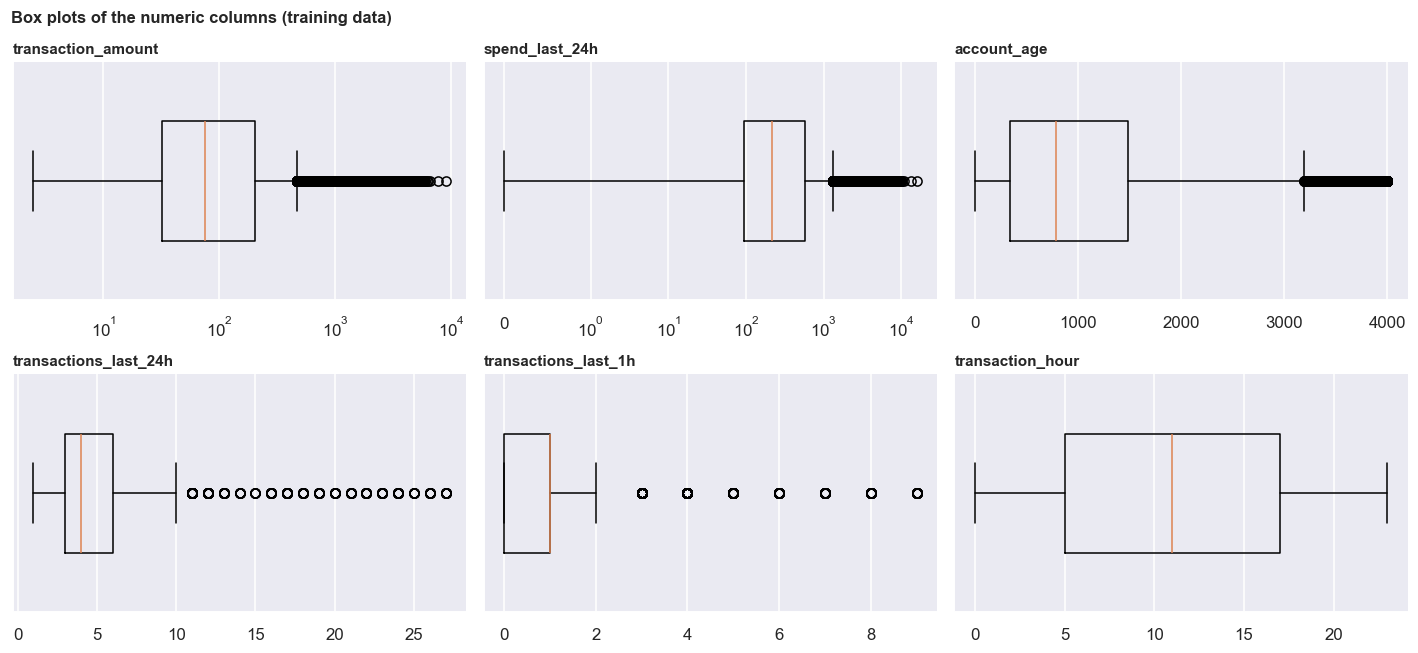

,median,mean,max,skew
transaction_amount,75.12,252.66,9000.00,5.61
spend_last_24h,217.52,555.26,15670.31,4.40
account_age,790.00,1053.65,4000.00,1.27
transactions_last_24h,4.00,4.64,27.00,3.11
transactions_last_1h,1.00,0.87,9.00,2.54
transaction_hour,11.00,11.45,23.00,-0.00


In [11]:
numeric_cols = ["transaction_amount", "spend_last_24h", "account_age",
                "transactions_last_24h", "transactions_last_1h", "transaction_hour"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.flat, numeric_cols):
    ax.boxplot(train[col].dropna(), widths=0.5, vert=False)
    if col in ("transaction_amount", "spend_last_24h"):
        ax.set_xscale("symlog", linthresh=1)   # log axis that also copes with values of 0
    ax.set_title(col)
    ax.set_yticks([])
fig.suptitle("Box plots of the numeric columns (training data)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

train[numeric_cols].agg(["median", "mean", "max", "skew"]).T.round(2)

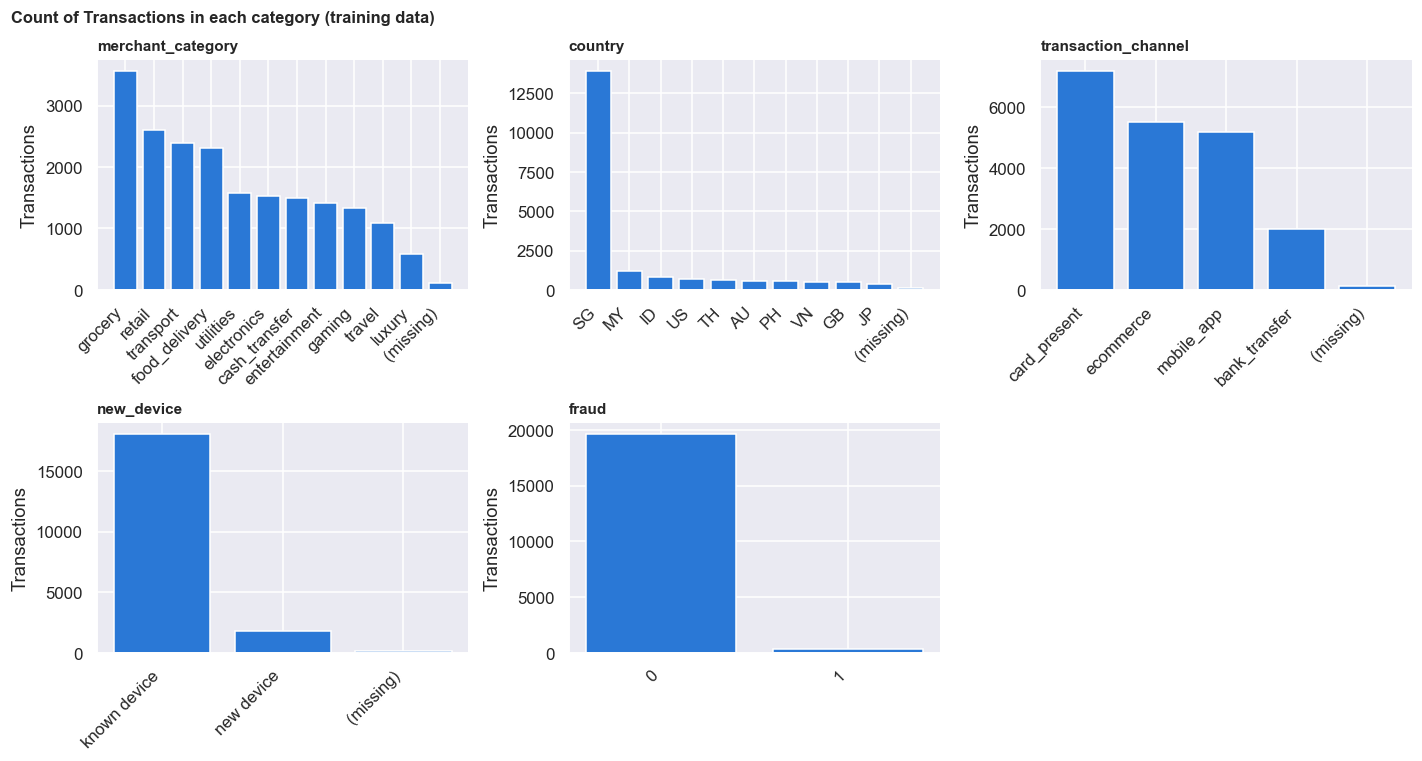

,most common,share
merchant_category,grocery,17.8%
country,SG,69.7%
transaction_channel,card_present,35.9%
new_device,0.0,90.4%
fraud,0,98.2%


In [12]:
categorical_cols = ["merchant_category", "country", "transaction_channel", "new_device", "fraud"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, categorical_cols):
    labels = train[col].map({0: "known device", 1: "new device"}) if col == "new_device" else train[col].astype(str)
    counts = labels.where(train[col].notna(), "(missing)").value_counts()
    ax.bar(counts.index, counts.values, color=HIGHLIGHT)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_title(col)
    ax.set_ylabel("Transactions")
axes.flat[-1].axis("off")
fig.suptitle("Count of Transactions in each category (training data)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

top = {col: train[col].value_counts(normalize=True, dropna=False) for col in categorical_cols}
pd.DataFrame({"most common": {c: s.index[0] for c, s in top.items()},
              "share": {c: f"{s.iloc[0]:.1%}" for c, s in top.items()}})

**Conclusion: the data is complete enough to use as it is.**

- **Ids:** all 20,000 are unique.
- **Missing values:** amount and hour are complete; the other eight feature columns are missing 0.53-0.80% of their values.
- **Ranges:** amounts run from 2.5 to 9,000, Account age from 5 to 4,000 days, the 24-hour count from 1 to 27 and the 1-hour count from 0 to 9.
- **Categories:** merchant category, country and channel have 11, 10 and 4 categories.

**What the distributions show:**

- **Amount and spend are heavily right-skewed:**
  - **amount:** median 75, mean 253, maximum 9,000 (skew 5.61);
  - **spend:** median 218, mean 555 (skew 4.40).
  
  Most Transactions are small, with a long tail of large ones that the box plots show as outliers.
- **The activity counts are small with a long tail:**
  - **24-hour count:** median 4, maximum 27;
  - **1-hour count:** median 1, maximum 9.
  
  The high values are rare bursts of activity.
- **Account age** has a median of 790 days. Its outliers cluster at the 4,000-day maximum.
- **Hour of day** is spread evenly (skew 0.00).
- **The categories are unbalanced:**
  - SG makes up 69.7% of Transactions;
  - card-present is the most common channel (35.9%);
  - grocery is the most common merchant (17.8%);
  - 90.4% are on a known device.
- **The `fraud` column itself is very unbalanced:** 98.2% of Transactions are legitimate. Further analysis on this is needed.

## 2.3 How rare is Fraud?

In [13]:
n_fraud = int(train["fraud"].sum())
print(f"Fraud: {n_fraud} of {len(train):,} Transactions = {fraud_rate:.3%} (about 1 in {round(1 / fraud_rate)})")
print(f"A model that never Flags anything: accuracy {1 - fraud_rate:.1%}, Recall 0%")
print(f"PR-AUC of a random guess (the floor to beat): {fraud_rate:.4f}")

Fraud: 353 of 20,000 Transactions = 1.765% (about 1 in 57)
A model that never Flags anything: accuracy 98.2%, Recall 0%
PR-AUC of a random guess (the floor to beat): 0.0176


**Conclusion: Fraud is rare, so accuracy is misleading.** Only 1.765% of Transactions are Fraud. A model that never Flags anything would score 98.2% accuracy while catching no Fraud at all. This confirms the brief's warning (section 1.1), and it is why we judge models on PR-AUC, F1 and Recall. It also sets the floor: a random guess scores a PR-AUC of only 0.0176.

## 2.4 Duplicates and missing values

In [14]:
print("Duplicate rows:", train.duplicated().sum(), "| duplicate ids:", train["id"].duplicated().sum())

missing = train.drop(columns=["id", "fraud"]).isna()
missing_table = pd.DataFrame({
    "missing rows": missing.sum(),
    "Fraud among them": [int(train.loc[missing[c], "fraud"].sum()) for c in missing.columns],
    "expected at average rate": (missing.sum() * fraud_rate).round(1),
})
missing_table[missing_table["missing rows"] > 0]

Duplicate rows: 0 | duplicate ids: 0


,missing rows,Fraud among them,expected at average rate
merchant_category,113,0,2.0
country,107,1,1.9
transaction_channel,123,4,2.2
transactions_last_24h,159,5,2.8
spend_last_24h,132,4,2.3
account_age,137,3,2.4
new_device,124,0,2.2
transactions_last_1h,142,4,2.5


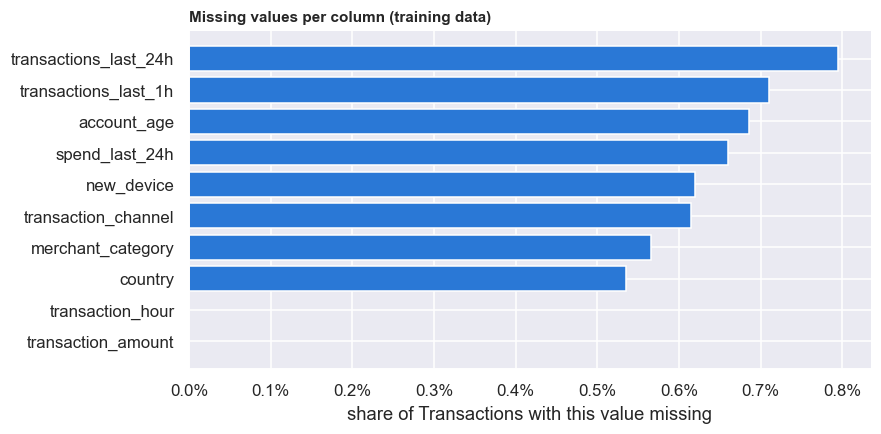

,Transactions,share
missing values in the row,,
0,19025,95.1%
1,913,4.6%
2,62,0.3%


In [15]:
feature_cols = train.columns.drop(["id", "fraud"])
missing_share = train[feature_cols].isna().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(missing_share.index, missing_share.values, color=HIGHLIGHT)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_xlabel("share of Transactions with this value missing")
ax.set_title("Missing values per column (training data)")
plt.show()

missing_per_row = train[feature_cols].isna().sum(axis=1).value_counts().sort_index()
pd.DataFrame({"Transactions": missing_per_row, "share": (missing_per_row / len(train)).map("{:.1%}".format)}) \
  .rename_axis("missing values in the row")

**Conclusion: no duplicates, and missing values look ordinary.** Missing values are rare and scattered. Amount and hour are complete, and the other eight columns are each missing 0.53-0.80% of values (chart). 19,025 Transactions (95.1%) have no missing value at all, 913 have one and only 62 have two. For most columns, the Fraud count among missing rows is close to what the average rate predicts. `merchant_category` and `new_device` show 0 where about 2 are expected, but that is too few rows to tell; section 3.3 tests whether it could be chance.

## 2.5 Fraud Rate by Category

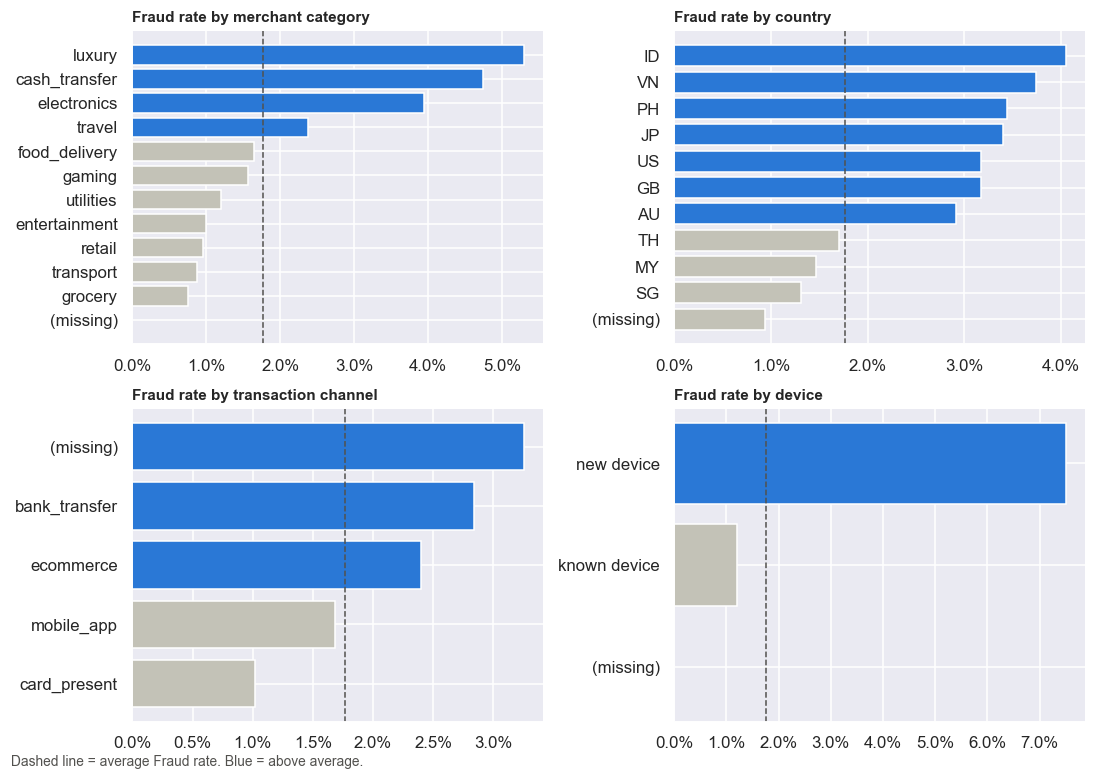

New device: 7.5% vs known device: 1.2% (6.2x)


Fraud rate
merchant_category   luxury              5.3%
                    cash_transfer       4.7%
                    electronics         3.9%
                    travel              2.4%
                    food_delivery       1.6%
                    gaming              1.6%
                    utilities           1.2%
                    entertainment       1.0%
                    retail              1.0%
                    transport           0.9%
                    grocery             0.8%
                    (missing)           0.0%
country             ID                  4.0%
                    VN                  3.7%
                    PH                  3.4%
                    JP                  3.4%
                    US                  3.2%
                    GB                  3.2%
                    AU                  2.9%
                    TH                  1.7%
                    MY                  1.5%
                    SG                  1.3%
                    (missing)           0.9%
transaction_channel (missing)           3.3%
                    bank_transfer       2.8%
                    ecommerce           2.4%
                    mobile_app          1.7%
                    card_present        1.0%
new_device          new device          7.5%
                    known device        1.2%
                    (missing)           0.0%

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
panels = [
    ("merchant_category", "Fraud rate by merchant category"),
    ("country", "Fraud rate by country"),
    ("transaction_channel", "Fraud rate by transaction channel"),
    ("new_device", "Fraud rate by device"),
]
category_rates = {}
for ax, (col, title) in zip(axes.flat, panels):
    values = train[col].map({0: "known device", 1: "new device"}) if col == "new_device" else train[col]
    rates = train.groupby(values.astype(object).fillna("(missing)"))["fraud"].mean().sort_values()
    category_rates[col] = rates
    plot_rates(ax, rates, title)
fig.text(0.01, 0.0, "Dashed line = average Fraud rate. Blue = above average.", color=INK)
fig.tight_layout()
plt.show()

device = category_rates["new_device"]
print(f"New device: {device['new device']:.1%} vs known device: {device['known device']:.1%} "
      f"({device['new device'] / device['known device']:.1f}x)")
pd.concat({col: r.sort_values(ascending=False) for col, r in category_rates.items()}).map("{:.1%}".format).to_frame("Fraud rate")

**Conclusion: several single features separate Fraud clearly.** Against the average of 1.765%:

- **New device:** 7.5% Fraud against 1.2% on known devices (6.2×), the strongest single signal.
- **Merchant category:** luxury (5.3%), cash transfer (4.7%) and electronics (3.9%) run 2-3× the average. Grocery (0.8%) is lowest.
- **Country:** every country except SG (1.3%), MY (1.5%) and TH (1.7%) is above average, led by ID (4.0%).
- **Channel:** bank transfer (2.8%) and e-commerce (2.4%) are above average; card-present (1.0%) is lowest.

Rows with a missing category are few (about 110-125 per column), so their rates are not reliable.

## 2.6 Fraud Rate by Hour of Day

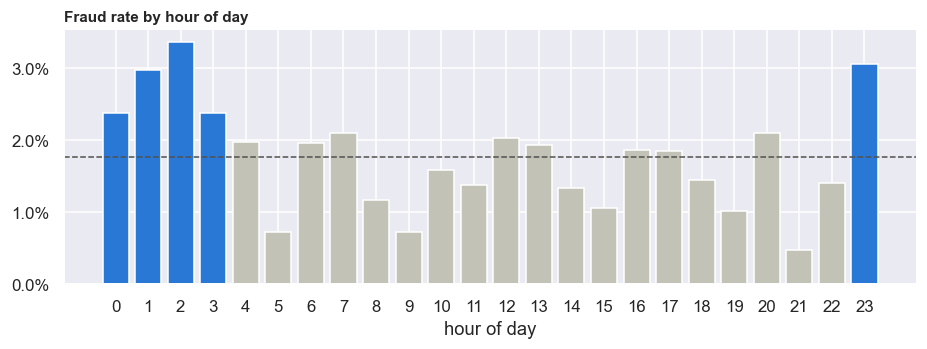

transaction_hour
2     3.36%
23    3.06%
1     2.97%
3     2.38%
0     2.38%
7     2.10%
Name: fraud, dtype: object

In [17]:
by_hour = train.groupby("transaction_hour")["fraud"].mean()
fig, ax = plt.subplots(figsize=(10, 3))
NIGHT = [23, 0, 1, 2, 3]
ax.bar(by_hour.index, by_hour.values, color=[HIGHLIGHT if h in NIGHT else NORMAL for h in by_hour.index])
ax.axhline(fraud_rate, color=INK, linestyle="--", linewidth=1)
ax.set_xticks(range(24))
ax.set_xlabel("hour of day")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_title("Fraud rate by hour of day")
plt.show()
by_hour.sort_values(ascending=False).head(6).map("{:.2%}".format)

**Conclusion: Fraud is most common late at night.** The five highest hours are 02:00 (3.36%), 23:00 (3.06%), 01:00 (2.97%), 03:00 and 00:00 (2.38% each). The next highest is 07:00 at 2.10%.

## 2.7 Fraud Rate Across the numeric features

Each feature is split into ten equal-sized groups.

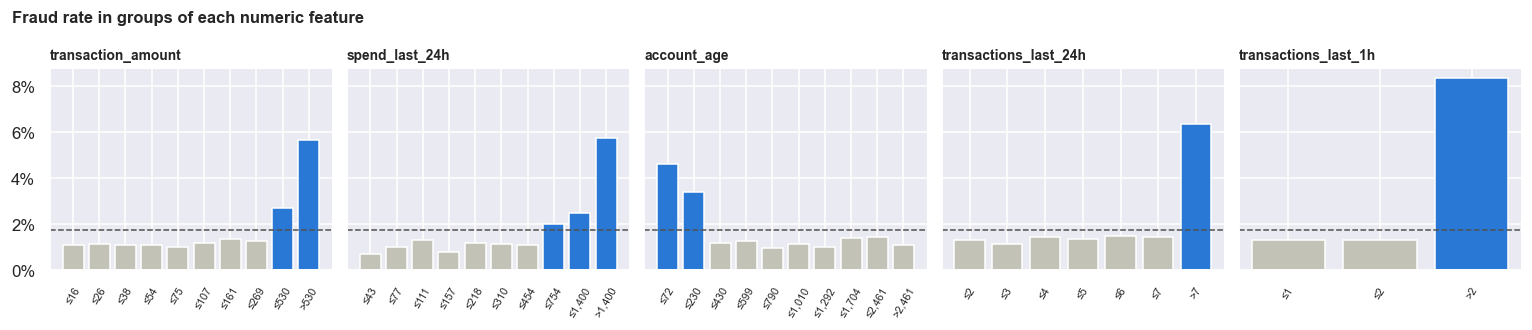

,transaction_amount,spend_last_24h,account_age,transactions_last_24h,transactions_last_1h
fraud,,,,,
legitimate (median),74.26,214.51,796.0,4.0,1.0
Fraud (median),224.26,662.82,335.5,5.0,1.0


Fraud rate in group
transaction_amount    ≤16                   1.1%
                      ≤26                   1.2%
                      ≤38                   1.1%
                      ≤54                   1.1%
                      ≤75                   1.0%
                      ≤107                  1.2%
                      ≤161                  1.4%
                      ≤269                  1.3%
                      ≤530                  2.7%
                      >530                  5.7%
spend_last_24h        ≤43                   0.7%
                      ≤77                   1.0%
                      ≤111                  1.3%
                      ≤157                  0.8%
                      ≤218                  1.2%
                      ≤310                  1.2%
                      ≤454                  1.1%
                      ≤754                  2.0%
                      ≤1,400                2.5%
                      >1,400                5.7%
account_age           ≤72                   4.6%
                      ≤230                  3.4%
                      ≤430                  1.2%
                      ≤599                  1.3%
                      ≤790                  1.0%
                      ≤1,010                1.2%
                      ≤1,292                1.0%
                      ≤1,704                1.4%
                      ≤2,461                1.5%
                      >2,461                1.1%
transactions_last_24h ≤2                    1.3%
                      ≤3                    1.1%
                      ≤4                    1.5%
                      ≤5                    1.4%
                      ≤6                    1.5%
                      ≤7                    1.4%
                      >7                    6.3%
transactions_last_1h  ≤1                    1.3%
                      ≤2                    1.3%
                      >2                    8.3%

In [18]:
numeric = ["transaction_amount", "spend_last_24h", "account_age",
           "transactions_last_24h", "transactions_last_1h"]
group_rates = {}
fig, axes = plt.subplots(1, 5, figsize=(14, 3), sharey=True)
for ax, col in zip(axes, numeric):
    groups = pd.qcut(train[col], q=10, duplicates="drop") # qcut first
    rates = train.groupby(groups, observed=True)["fraud"].mean()
    ax.bar(range(len(rates)), rates.values, color=[HIGHLIGHT if r > fraud_rate else NORMAL for r in rates.values])
    ax.axhline(fraud_rate, color=INK, linestyle="--", linewidth=1)
    labels = [f"≤{iv.right:,.0f}" for iv in rates.index[:-1]] + [f">{rates.index[-1].left:,.0f}"]
    ax.set_xticks(range(len(rates)), labels, rotation=60, fontsize=7)
    group_rates[col] = pd.Series(rates.values, index=labels)
    ax.set_title(col, fontsize=9)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
fig.suptitle("Fraud rate in groups of each numeric feature",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()
display(train.groupby("fraud")[numeric].median().rename(index={0: "legitimate (median)", 1: "Fraud (median)"}))
pd.concat(group_rates).map("{:.1%}".format).to_frame("Fraud rate in group")

**Conclusion: Fraud concentrates at the extremes of the numeric features.**

- **Amount:** above 530 (the top group) the Fraud rate is 5.7%, against about 1.0-1.4% for most amounts. The median Fraud amount is 224, against 74 for legitimate Transactions.
- **24-hour spend:** above 1,400 it is 5.7%.
- **Account age:** young Accounts of 72 days or less run at 4.6%, and 72-230 days at 3.4%. The median Fraud Account is 336 days old, against 796.
- **Activity:** more than 7 Transactions in 24 hours means 6.3%, and more than 2 in the last hour 8.3%. Below those levels the rate is flat.
- **Skew:** amounts are heavily skewed. Nine of the ten amount groups end at or below 530, while the maximum is 9,000 (2.2).

## 2.8 Data-quality checks

In [19]:
t24, t1h = train["transactions_last_24h"], train["transactions_last_1h"]
zero_spend = train["spend_last_24h"] == 0
max_age = train["account_age"] == 4000

checks = pd.Series({
    "lowest transactions_last_24h": t24.min(),
    "rows where last_1h > last_24h": (t1h > t24).sum(),
    "rows with spend_last_24h = 0": zero_spend.sum(),
    "  ...of which transactions_last_24h = 1": (zero_spend & (t24 == 1)).sum(),
    "rows with account_age exactly 4000 (the maximum)": max_age.sum(),
    "  ...of which Fraud": (max_age & (train["fraud"] == 1)).sum(),
})
display(checks.to_frame("value"))

print("Accounts whose only transaction in 24h is this one, by their last-1h count:")
t1h[t24 == 1].value_counts().sort_index()

,value
lowest transactions_last_24h,1.0
rows where last_1h > last_24h,0.0
rows with spend_last_24h = 0,557.0
...of which transactions_last_24h = 1,552.0
rows with account_age exactly 4000 (the maximum),354.0
...of which Fraud,2.0


Accounts whose only transaction in 24h is this one, by their last-1h count:


transactions_last_1h
0.0    587
1.0    191
Name: count, dtype: int64

**Conclusion: the activity columns are only approximately consistent.**

- **24-hour count:** never below 1, so it includes the current Transaction.
- **24-hour spend:** 0 in 557 rows, 552 of them with a 24-hour count of 1. So spend excludes the current Transaction.
- **1-hour count:** never above the 24-hour count, as nested windows should be. But Accounts whose only Transaction in 24 hours is this one show a 1-hour count of 0 (587 rows) or 1 (191 rows), so it does not follow one definition. We treat these columns as approximate, likely synthetic.
- **Account age:** 354 rows sit exactly at the maximum of 4000 days, which looks like a cap. Only 2 of them are Fraud.

## 2.9 Key Observations

A recap of the conclusions above.

1. **Fraud is rare:** 353 of 20,000 Transactions (1.765%, about 1 in 57). Never Flagging anything would score 98.2% accuracy, which is why accuracy is useless here. A random guess scores a PR-AUC of 0.018.
2. **Several single features separate Fraud clearly:**
   - **New device:** 7.5% Fraud against 1.2% (about 6×)
   - **Merchant category:** luxury 5.3%, cash transfer 4.7%, electronics 3.9%
   - **Country:** every country except SG, MY and TH is above average
   - **Channel:** bank transfer and e-commerce are above average
   - **Hour:** late at night (23:00-03:00, 2.4-3.4%)
3. **Fraud concentrates at the extremes of the numeric features:**
   - **Amount:** the top decile, above 530 (5.7%)
   - **Account age:** young Accounts of 230 days or less (3.4-4.6%)
   - **Bursts of activity:** more than 7 Transactions in 24 hours (6.3%), or more than 2 in the last hour (8.3%)
   
   Amounts are heavily skewed (median 75, maximum 9,000).
4. **Missing values are rare** (0.5-0.8% per column). Rows missing `new_device` or `merchant_category` contain no Fraud where about 2 would be expected, but that is too few rows to read anything into.
5. **Data quality:**
   - There are no duplicates.
   - The 24-hour count is never 0, so it includes the current Transaction.
   - 24-hour spend is 0 almost only when that count is 1, so spend excludes the current Transaction.
   - The 1-hour count is inconsistent: Accounts with only this Transaction show 0 (587 rows) or 1 (191 rows). We treat the activity columns as approximate.
   - Account age stops at 4000 days, which looks like a cap.

# 3. Clean and preprocess the data

## 3.1 Missing Value

In [20]:
NUMERIC_RAW = ["transaction_amount", "transaction_hour", "transactions_last_24h", "spend_last_24h",
               "account_age", "new_device", "transactions_last_1h"]
CATEGORICAL = ["merchant_category", "country", "transaction_channel"]

for col in CATEGORICAL + NUMERIC_RAW:
    is_missing = train[col].isna()
    n, k = int(is_missing.sum()), int(train.loc[is_missing, "fraud"].sum())
    if n and k == 0:
        print(f"{col}: {n} missing rows, 0 Fraud. "
              f"Chance of seeing 0 Fraud in {n} ordinary rows: {(1 - fraud_rate) ** n:.0%}")

merchant_category: 113 missing rows, 0 Fraud. Chance of seeing 0 Fraud in 113 ordinary rows: 13%
new_device: 124 missing rows, 0 Fraud. Chance of seeing 0 Fraud in 124 ordinary rows: 11%


**Decision: fill missing values with ordinary values, and add no "was missing" flags.**

- A chance of 11-13% means the "no Fraud when missing" pattern is likely luck, not a real signal. A "was missing" flag would let the model learn it anyway
- Numeric columns are filled with the **median** and categories with the **most frequent category**. Both are computed from the training data only, inside the model pipeline..

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Reference (left-out) category per column, in CATEGORICAL order: the most common one.
REFERENCE = [train[col].mode()[0] for col in CATEGORICAL]

def build_preprocessor(numeric_cols):
    """Fill missing values, scale numbers, one-hot encode the CATEGORICAL columns. Learned from training data only."""
    numeric = Pipeline([("fill", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(drop=REFERENCE, handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("numeric", numeric, numeric_cols),
                              ("categorical", categorical, CATEGORICAL)])

print("Reference categories:", dict(zip(CATEGORICAL, REFERENCE)))

# Quick check on the raw columns (section 4 adds the engineered features).
preprocessor_check = build_preprocessor(NUMERIC_RAW).fit(train)
check_out = preprocessor_check.transform(train)
print("Model input:", check_out.shape[0], "rows x", check_out.shape[1], "columns; missing values left:",
      int(np.isnan(check_out).sum()))

Reference categories: {'merchant_category': 'grocery', 'country': 'SG', 'transaction_channel': 'card_present'}
Model input: 20000 rows x 29 columns; missing values left: 0


# 4. Engineer useful features

| Feature | Formula | Why |
|---|---|---|
| `log_amount` | log(1 + amount) | Amounts are heavily skewed (median 75, maximum 9,000). The log compresses the long tail, so a few huge amounts do not dominate a linear model |
| `amount_vs_spend_24h` | log(1 + amount) − log(1 + spend in last 24h) | How large this Transaction is **relative to the Account's own recent spending**. 24-hour spend excludes the current Transaction, so the comparison is fair |
| `log_account_age` | log(1 + account age) | Fraud concentrates in young Accounts. The log stretches out the young end, where the risk changes fastest |
| `hour_sin`, `hour_cos` | position of the hour on a 24-hour circle | Hour is cyclical: 23:00 and 00:00 are neighbours, but as plain numbers they are 23 apart |
| `is_night` | 1 if the hour is 23, 0, 1, 2 or 3 | Fraud peaks late at night|

The raw columns stay in as well. A burst of activity (many Transactions in the last 1h or 24h) is already captured by the raw counts.

## 4.2 `make_features`: the function the organisers run

This is the **only** feature code used at prediction time (the same function lives in `src/fraud_detection/features.py`). The organisers copy it into their notebook and apply it to the Private Test Set before calling our model. So it:

- is **self-contained**: imports inside, no variables from elsewhere in the notebook;
- guards against bad values the Private Test Set may contain: text in a numeric column becomes missing, values are kept inside the range seen in training, and infinities are removed;
- never uses the `fraud` column;
- never drops or reorders rows, so each prediction lines up with its Transaction.

In [22]:
def make_features(df):
    """Guard against bad values, then add the engineered features (section 4.1)."""
    import numpy as np
    import pandas as pd

    numeric = ["transaction_amount", "transaction_hour", "transactions_last_24h", "spend_last_24h",
               "account_age", "new_device", "transactions_last_1h"]
    categorical = ["merchant_category", "country", "transaction_channel"]
    out = df.copy()

    # Guards against bad values in unseen data
    for col in numeric:
        out[col] = pd.to_numeric(out[col], errors="coerce").astype(float)   # text -> missing
    for col in categorical:
        values = out[col].astype(object)
        out[col] = values.astype(str).where(values.notna(), np.nan)          # categories as text
    training_max = {"transaction_amount": 9000.0, "spend_last_24h": 15670.31, "account_age": 4000.0,
                    "transactions_last_24h": 27.0, "transactions_last_1h": 9.0}       # from section 2.2
    for col, upper in training_max.items():
        out[col] = out[col].clip(lower=0, upper=upper)                       # stay inside the training range

    # Engineered features (4.1)
    hour = out["transaction_hour"]
    out["log_amount"] = np.log1p(out["transaction_amount"])
    out["amount_vs_spend_24h"] = np.log1p(out["transaction_amount"]) - np.log1p(out["spend_last_24h"])
    out["log_account_age"] = np.log1p(out["account_age"])
    out["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    out["is_night"] = hour.isin([23, 0, 1, 2, 3]).astype(float).where(hour.notna())

    # Extra features for the final model (section 7.6)
    out["avg_spend_per_txn"] = np.log1p(out["spend_last_24h"] / out["transactions_last_24h"].clip(lower=1))
    out["amount_vs_avg_txn"] = out["log_amount"] - out["avg_spend_per_txn"]
    out["share_last_1h"] = out["transactions_last_1h"] / out["transactions_last_24h"].clip(lower=1)
    out["newdev_x_logamt"] = out["new_device"].fillna(0) * out["log_amount"]
    out["young_x_newdev"] = out["new_device"].fillna(0) * (out["account_age"] < 230)

    # No infinities
    engineered = ["log_amount", "amount_vs_spend_24h", "log_account_age", "hour_sin", "hour_cos", "is_night",
                  "avg_spend_per_txn", "amount_vs_avg_txn", "share_last_1h", "newdev_x_logamt", "young_x_newdev"]
    out[numeric + engineered] = out[numeric + engineered].replace([np.inf, -np.inf], np.nan)
    return out

## 4.3 The model's inputs


In [23]:
NUMERIC_FEATURES = NUMERIC_RAW + ["log_amount", "amount_vs_spend_24h", "log_account_age",
                                  "hour_sin", "hour_cos", "is_night"]
FEATURE_NAMES = NUMERIC_FEATURES + CATEGORICAL

train_features = make_features(train)
X = train_features[FEATURE_NAMES]
y = train["fraud"].astype(int)
print(f"{X.shape[1]} input columns ({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL)} categorical) for {len(X):,} Transactions")

skew = pd.DataFrame({"skew before log": [train["transaction_amount"].skew(), train["account_age"].skew()],
                     "skew after log": [X["log_amount"].skew(), X["log_account_age"].skew()]},
                    index=["amount", "account age"]).round(2)
display(skew)
print("Fraud rate at night:", f"{y[X['is_night'] == 1].mean():.2%}", "| rest of the day:", f"{y[X['is_night'] == 0].mean():.2%}")

16 input columns (13 numeric, 3 categorical) for 20,000 Transactions


,skew before log,skew after log
amount,5.61,0.47
account age,1.27,-0.99


Fraud rate at night: 2.81% | rest of the day: 1.49%


**Conclusion: the features do what they were designed for.**

- **`log_amount`:** the log removes most of the amount's skew (5.61 → 0.47).
- **`log_account_age`:** for account age it slightly overshoots (1.27 → −0.99, now skewed the other way), but it still spreads out the young Accounts where the risk is.
- **`is_night`:** separates Fraud on its own (2.81% at night vs 1.49% for the rest of the day).

Whether the features improve the model as a whole is tested in section 6, by comparing the model with and without them.

In [24]:
# The cleaning rules must leave every real value untouched: they only act on values outside the training range.
def unchanged(raw):
    cleaned = make_features(raw)[NUMERIC_RAW]
    as_numbers = raw[NUMERIC_RAW].apply(pd.to_numeric, errors="coerce")
    return int((cleaned.fillna(-1) != as_numbers.fillna(-1)).sum().sum())
print("Values changed by the cleaning rules: training", unchanged(train))

Values changed by the cleaning rules: training 0


**Conclusion: `make_features` survives bad data without changing good data.**

# 5. Build a baseline model

## 5.1 How every model is evaluated

To compare models fairly, every model in sections 5 and 6 is scored on **the same 15 train/validation splits**: 5-fold stratified cross-validation, repeated 3 times. Each validation fold holds about 70 Frauds (printed below), and every result is reported as **mean ± standard deviation** across the 15 folds. A single split would hold too few Frauds to tell models apart reliably; the spread across folds in 5.3 (± 0.038 in PR-AUC) shows how much one split can vary.

- **PR-AUC** is the main comparison metric, because it measures ranking quality independently of any threshold.
- **F1 and Recall are shown at the default threshold of 0.5**, to show what happens without a deliberate choice.

In [25]:
from sklearn.model_selection import StratifiedKFold

N_SPLITS, N_REPEATS = 5, 3
FOLDS = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=42).split(X, y))
frauds_per_fold = [int(y.iloc[valid_idx].sum()) for _, valid_idx in FOLDS]
print(f"{len(FOLDS)} folds; Frauds per validation fold: {min(frauds_per_fold)} to {max(frauds_per_fold)}")

def fold_metrics(truth, score, threshold):
    """Metrics for one validation fold, Flagging every Transaction whose Fraud Score is >= threshold."""
    flags = (score >= threshold).astype(int)
    return {"PR-AUC": average_precision_score(truth, score),
            "F1": f1_score(truth, flags, zero_division=0),
            "Recall": recall_score(truth, flags),
            "Precision": precision_score(truth, flags, zero_division=0),
            "Flags": int(flags.sum())}

def score_folds(fraud_scores, threshold=0.5):
    """fraud_scores(fold_number, train_idx, valid_idx) returns Fraud Scores for the validation rows. One row per fold."""
    return pd.DataFrame([fold_metrics(y.iloc[valid_idx], fraud_scores(k, train_idx, valid_idx), threshold)
                         for k, (train_idx, valid_idx) in enumerate(FOLDS)])

def evaluate_model(make_model):
    """Train a fresh model on each training fold and score its validation fold."""
    def fraud_scores(k, train_idx, valid_idx):
        model = make_model().fit(X.iloc[train_idx], y.iloc[train_idx])
        return model.predict_proba(X.iloc[valid_idx])[:, 1]
    return score_folds(fraud_scores)

def summarise(results, metrics=("PR-AUC", "F1", "Recall"), label=" at 0.5"):
    """Mean ± standard deviation of each metric across the folds. PR-AUC never depends on the threshold."""
    metrics = list(metrics)
    table = pd.DataFrame({name: r[metrics].mean().map("{:.3f}".format) + " ± " + r[metrics].std().map("{:.3f}".format)
                          for name, r in results.items()}).T
    return table.rename(columns={m: m + label for m in metrics if m != "PR-AUC"})

results = {}

15 folds; Frauds per validation fold: 70 to 71


## 5.2 Simplest Guess of fraud
**"Flag every Transaction from a new device"**. This is the strongest single signal from section 2.5. A model has to beat this to justify itself.

In [26]:
results["Rule: Flag every new device"] = score_folds(
    lambda k, train_idx, valid_idx: X["new_device"].iloc[valid_idx].fillna(0).to_numpy())
summarise(results)

,PR-AUC,F1 at 0.5,Recall at 0.5
Rule: Flag every new device,0.040 ± 0.009,0.126 ± 0.022,0.382 ± 0.059


**Conclusion: the rule beats a random guess but makes many wrong Flags.** Its PR-AUC of 0.040 is above the random-guess floor of 0.018, and it catches 38% of Fraud (Recall 0.382). But most of its Flags are legitimate Transactions, so F1 is only 0.126. Any real model must do better than this.

## 5.3 Logistic regression baseline

**Why logistic regression first?** It is the simplest real model for a yes/no outcome. It is fast and well understood, and every prediction can be explained: each feature multiplies the odds of Fraud by a fixed amount.

**Its assumptions, and how we meet them:**

| Assumption | In our data |
|---|---|
| Each feature's effect on the *log-odds* of Fraud is a straight line | Skewed amounts and account ages are log-transformed, and the hour is encoded as a circle |
| Features are not near-duplicates of each other (low multicollinearity) | Not fully met: some features overlap (e.g. amount and log amount), so individual coefficients should be read with care. The model's overall ranking is what we compare |
| Transactions are independent of each other | Assumed: the data has no Account identifier to group by |

In [27]:
def with_preprocessing(model, numeric=NUMERIC_FEATURES):
    """Preprocessing (section 3.2) followed by a model, as one pipeline."""
    return Pipeline([("prep", build_preprocessor(numeric)), ("model", model)])

def logistic_regression():
    return with_preprocessing(LogisticRegression(max_iter=1000))

results["Logistic regression"] = evaluate_model(logistic_regression)
display(summarise(results))

wins = (results["Logistic regression"]["PR-AUC"] > results["Rule: Flag every new device"]["PR-AUC"]).sum()
print(f"Logistic regression ranks Fraud better than the rule in {wins} of {len(FOLDS)} folds.")
print(f"Its PR-AUC is {results['Logistic regression']['PR-AUC'].mean() / fraud_rate:.1f}x the random-guess floor.")
print(f"At threshold 0.5 it Flags on average {results['Logistic regression']['Flags'].mean():.0f} "
      f"of about {len(y) // N_SPLITS:,} Transactions per fold.")

,PR-AUC,F1 at 0.5,Recall at 0.5
Rule: Flag every new device,0.040 ± 0.009,0.126 ± 0.022,0.382 ± 0.059
Logistic regression,0.228 ± 0.038,0.170 ± 0.039,0.097 ± 0.025


Logistic regression ranks Fraud better than the rule in 15 of 15 folds.
Its PR-AUC is 12.9x the random-guess floor.
At threshold 0.5 it Flags on average 9 of about 4,000 Transactions per fold.


A precision-recall curve shows the precision and Recall the model would reach at every possible threshold; PR-AUC is the area under it. Each Transaction is scored by a model that never saw it in training (the first round of the 5 folds), so the curve is honest. The rule has only one setting, so it is a single point; a random guess is the flat line at the Fraud rate.

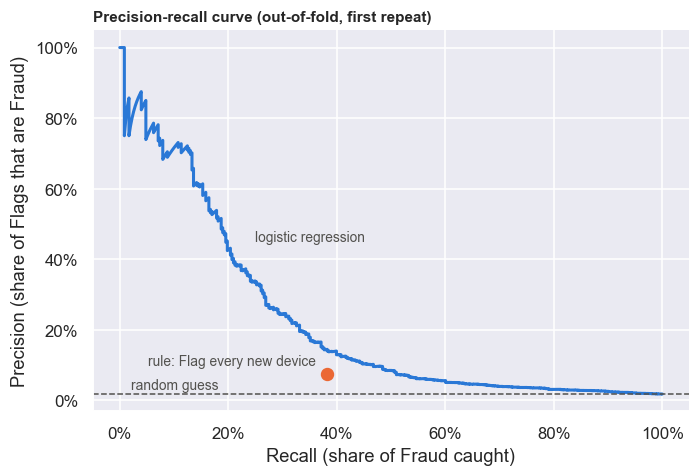

Area under this curve (PR-AUC): 0.222
Rule: Recall 38.2%, precision 7.5%
Best logistic regression precision at the rule's Recall or higher: 14.4%


In [28]:
from sklearn.metrics import precision_recall_curve

oof_baseline = np.zeros(len(y))
for train_idx, valid_idx in FOLDS[:N_SPLITS]:   # first repeat: every Transaction scored exactly once
    oof_baseline[valid_idx] = logistic_regression().fit(X.iloc[train_idx], y.iloc[train_idx]).predict_proba(X.iloc[valid_idx])[:, 1]

curve_precision, curve_recall, _ = precision_recall_curve(y, oof_baseline)
rule_flags = X["new_device"].fillna(0).astype(int)
rule_recall, rule_precision = recall_score(y, rule_flags), precision_score(y, rule_flags)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(curve_recall, curve_precision, color=HIGHLIGHT, linewidth=2)
ax.text(0.25, 0.45, "logistic regression", color=INK)
ax.scatter([rule_recall], [rule_precision], color="#eb6834", s=60, zorder=3)
ax.text(rule_recall - 0.02, rule_precision + 0.035, "rule: Flag every new device", color=INK, ha="right", va="center")
ax.axhline(fraud_rate, color=INK, linestyle="--", linewidth=1)
ax.text(0.02, fraud_rate + 0.015, "random guess", color=INK)
ax.set_xlabel("Recall (share of Fraud caught)")
ax.set_ylabel("Precision (share of Flags that are Fraud)")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Precision-recall curve (out-of-fold, first repeat)")
plt.show()

print(f"Area under this curve (PR-AUC): {average_precision_score(y, oof_baseline):.3f}")
print(f"Rule: Recall {rule_recall:.1%}, precision {rule_precision:.1%}")
print(f"Best logistic regression precision at the rule's Recall or higher: {curve_precision[curve_recall >= rule_recall].max():.1%}")

**Conclusion: the model's curve sits well above both the rule and random guessing.**

- **The rule:** catches 38.2% of Fraud, but only 7.5% of its Flags are Fraud.
- **The model at the same Recall:** reaches 14.4% precision, about **twice as precise**.
- **The model's highest-scored Transactions:** mostly Fraud, which is why the curve starts high on the left.
- **Area under this curve:** PR-AUC 0.222. This uses one round of 5 folds pooled together, so it differs slightly from the 0.228 average over all 15 folds above.

## 5.4 What the baseline learned

Each bar shows how much a feature multiplies the **odds** of Fraud:

- **numeric features:** per one standard deviation increase;
- **categories:** compared with the reference category of the same column (grocery, SG, card-present), i.e. a typical Transaction.

Bars to the right of 1 raise the Fraud Score; bars to the left lower it.

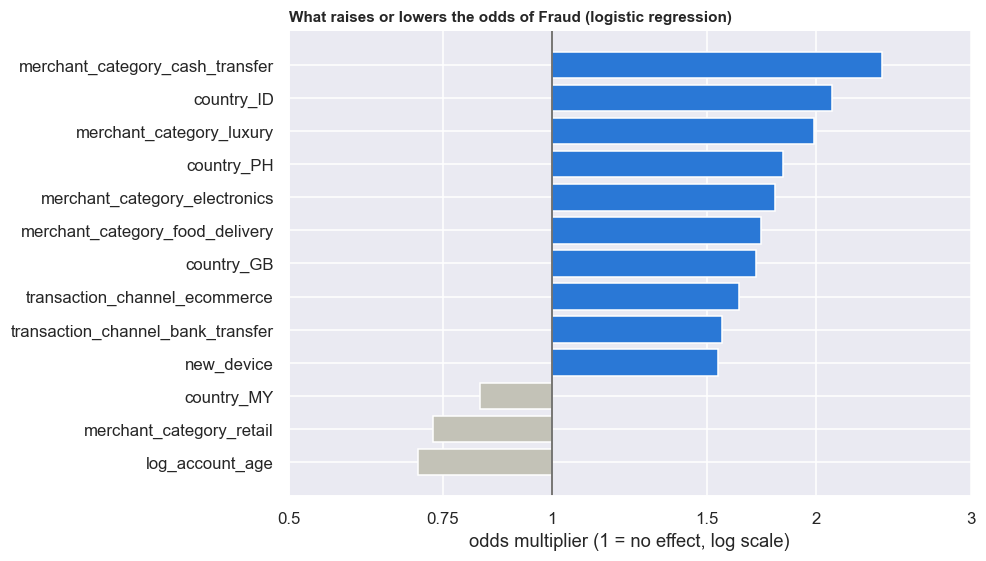

log_account_age                      0.70
merchant_category_retail             0.73
country_MY                           0.83
transaction_amount                   0.99
account_age                          1.00
country_TH                           1.01
merchant_category_transport          1.02
merchant_category_entertainment      1.03
amount_vs_spend_24h                  1.05
hour_cos                             1.06
country_AU                           1.07
spend_last_24h                       1.07
merchant_category_utilities          1.08
transaction_hour                     1.08
transactions_last_1h                 1.08
hour_sin                             1.09
merchant_category_gaming             1.15
transactions_last_24h                1.24
merchant_category_travel             1.29
is_night                             1.29
country_US                           1.33
transaction_channel_mobile_app       1.42
log_amount                           1.50
country_JP                        

In [29]:
baseline = logistic_regression().fit(X, y)
names = [n.split("__", 1)[1] for n in baseline.named_steps["prep"].get_feature_names_out()]
odds = pd.Series(np.exp(baseline.named_steps["model"].coef_[0]), index=names).sort_values()  # np.exp returns a new array
# Every feature that clearly lowers the odds (below 0.95), plus the ten that raise them most.
shown = pd.concat([odds[odds < 0.95], odds.tail(10)])

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(shown.index, shown.values - 1, left=1, color=[HIGHLIGHT if v > 1 else NORMAL for v in shown.values])
ax.axvline(1, color=INK, linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3], ["0.5", "0.75", "1", "1.5", "2", "3"])
ax.minorticks_off()
ax.set_xlabel("odds multiplier (1 = no effect, log scale)")
ax.set_title("What raises or lowers the odds of Fraud (logistic regression)")
plt.show()
odds.round(2)

## 5.5 Baseline takeaways

- **The model ranks Fraud far better than the rule:** PR-AUC 0.228 against 0.040, better in all 15 folds, and about 13× the random-guess floor of 0.018.
- **It learned the patterns from section 2.** Compared with a typical Transaction (grocery, SG, card-present), the largest effects raising the odds of Fraud are cash transfers (×2.38), Indonesia (×2.08) and luxury merchants (×1.99). New devices (×1.55) and large amounts (`log_amount`, ×1.50 per standard deviation, just below the ten shown) follow. Only older Accounts (×0.70 per standard deviation), retail merchants (×0.73) and Malaysia (×0.83) clearly lower them.
- **At the default threshold of 0.5 it is almost useless as a Flagger.** It Flags only about 9 of 4,000 Transactions per fold, so Recall is under 10%. Fraud is rare, so very few Fraud Scores ever reach 0.5.

# 6. Train & Compare models

## 6.1 The candidates

Each candidate tests one specific question. All of them use the same features, the same preprocessing and the same 15 folds as the baseline.

| Candidate | Question it answers |
|---|---|
| Logistic regression on the **raw columns only** | Do the engineered features from section 4 help? |
| Logistic regression with **class weights** (`balanced`) | Does telling the model that Fraud is rare improve its ranking? |
| **Random Forest** (300 trees, depth 16, class weights) | Do many independent decision trees find patterns the linear model misses? |
| **Gradient Boosting** (150 trees, depth 5, learning rate 0.05) | Do trees built one after another, each correcting the last, find combinations of features the linear model cannot? |
| **Gradient Boosting + SMOTE** | Does adding synthetic Fraud examples to the training folds help? |

SMOTE creates new Frauds by interpolating between real ones, until there is 1 Fraud for every 10 legitimate Transactions (about 9% of the training fold). It is applied **inside** each training fold only, never to the validation fold

In [30]:
def random_forest():
    return RandomForestClassifier(n_estimators=300, max_depth=16, class_weight="balanced", random_state=42, n_jobs=-1)

def gradient_boosting():
    return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=5, random_state=42)

def gradient_boosting_smote():
    # SMOTE has to sit between preprocessing and the model, so this pipeline is built step by step.
    return ImbPipeline([("prep", build_preprocessor(NUMERIC_FEATURES)),
                        ("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
                        ("model", gradient_boosting())])

# "Raw columns only" ignores the engineered features, so the preprocessor only receives the raw numeric columns.
results["LR, raw columns only"] = evaluate_model(lambda: with_preprocessing(LogisticRegression(max_iter=1000), NUMERIC_RAW))
results["LR, class weights"] = evaluate_model(lambda: with_preprocessing(LogisticRegression(max_iter=1000, class_weight="balanced")))
results["Random Forest"] = evaluate_model(lambda: with_preprocessing(random_forest()))
results["Gradient Boosting"] = evaluate_model(lambda: with_preprocessing(gradient_boosting()))
results["Gradient Boosting + SMOTE"] = evaluate_model(gradient_boosting_smote)

**What SMOTE does to a training fold.** Counts in the first training fold before and after SMOTE (the validation fold is never touched):

In [31]:
train_idx, _ = FOLDS[0]
fold_prep = build_preprocessor(NUMERIC_FEATURES).fit(X.iloc[train_idx])
_, y_smote = SMOTE(sampling_strategy=0.1, random_state=42).fit_resample(fold_prep.transform(X.iloc[train_idx]), y.iloc[train_idx])
pd.DataFrame({"before SMOTE": y.iloc[train_idx].value_counts(), "after SMOTE": pd.Series(y_smote).value_counts()}) \
  .rename(index={0: "legitimate", 1: "Fraud"})

,before SMOTE,after SMOTE
fraud,,
legitimate,15717,15717
Fraud,283,1571


SMOTE leaves the 15,717 legitimate Transactions untouched and adds 1,288 synthetic Frauds to the 283 real ones (1,571 in total), giving 1 Fraud for every 10 legitimate Transactions. More than four in five Frauds the model learns from are therefore synthetic.

## 6.2 Results

In [32]:
table = summarise(results)
baseline_pr_auc = results["Logistic regression"]["PR-AUC"]
table["folds beating the baseline (PR-AUC)"] = [
    "-" if name == "Logistic regression" else f"{(r['PR-AUC'] > baseline_pr_auc).sum()} of {len(FOLDS)}"
    for name, r in results.items()]
table.sort_values("PR-AUC", ascending=False)

,PR-AUC,F1 at 0.5,Recall at 0.5,folds beating the baseline (PR-AUC)
Logistic regression,0.228 ± 0.038,0.170 ± 0.039,0.097 ± 0.025,-
"LR, class weights",0.215 ± 0.038,0.089 ± 0.006,0.626 ± 0.044,2 of 15
"LR, raw columns only",0.207 ± 0.035,0.157 ± 0.036,0.090 ± 0.023,0 of 15
Gradient Boosting,0.203 ± 0.041,0.152 ± 0.043,0.087 ± 0.027,2 of 15
Gradient Boosting + SMOTE,0.198 ± 0.044,0.215 ± 0.040,0.131 ± 0.029,2 of 15
Random Forest,0.178 ± 0.044,0.149 ± 0.052,0.084 ± 0.031,1 of 15
Rule: Flag every new device,0.040 ± 0.009,0.126 ± 0.022,0.382 ± 0.059,0 of 15


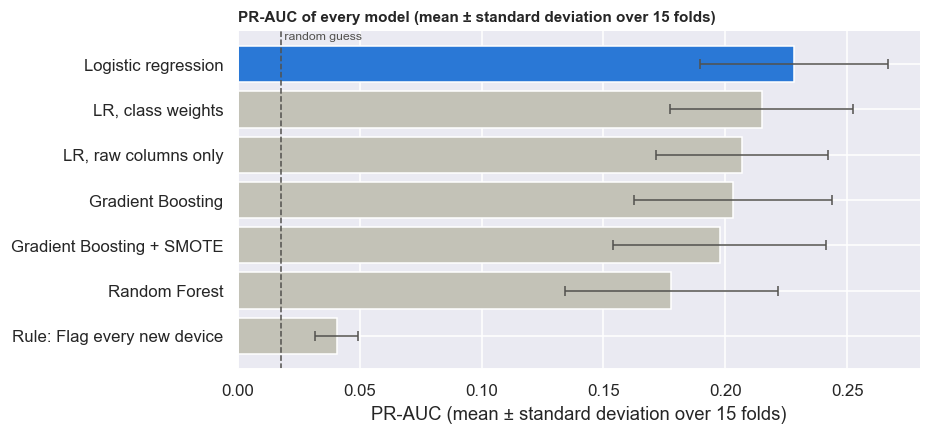

In [33]:
order = sorted(results, key=lambda name: results[name]["PR-AUC"].mean())
means = [results[name]["PR-AUC"].mean() for name in order]
spread = [results[name]["PR-AUC"].std() for name in order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(order, means, xerr=spread, color=[HIGHLIGHT if n == "Logistic regression" else NORMAL for n in order],
        error_kw={"ecolor": INK, "linewidth": 1, "capsize": 3})
ax.axvline(fraud_rate, color=INK, linestyle="--", linewidth=1)
ax.text(fraud_rate, len(order) - 0.45, " random guess", color=INK, fontsize=8)
ax.set_xlabel("PR-AUC (mean ± standard deviation over 15 folds)")
ax.set_title("PR-AUC of every model (mean ± standard deviation over 15 folds)")
plt.show()

**Where do the models differ?** The bar chart compares one number per model. Precision-recall curves (as in 5.3, out-of-fold, first repeat) show the whole trade-off for the main candidates.

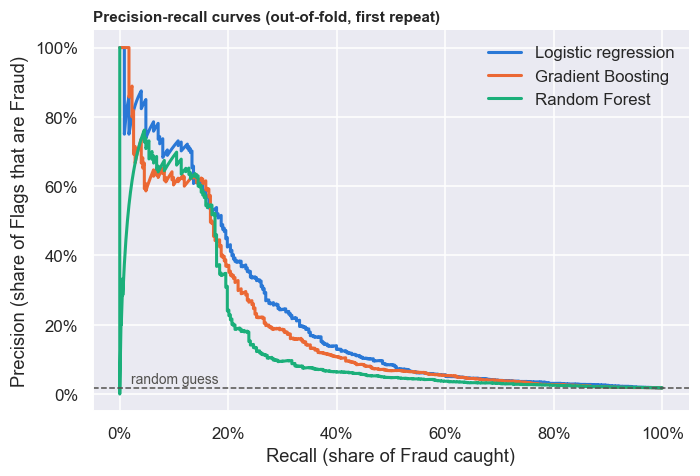

,PR-AUC,precision at 10% Recall,precision at 25% Recall,precision at 40% Recall
Logistic regression,0.222,73.1%,33.6%,13.0%
Gradient Boosting,0.194,63.3%,23.2%,10.8%
Random Forest,0.161,69.8%,13.4%,6.4%


In [34]:
def oof_first_repeat(make_model):
    """Out-of-fold Fraud Scores from the first repeat: every Transaction scored once, by a model that never saw it."""
    scores = np.zeros(len(y))
    for train_idx, valid_idx in FOLDS[:N_SPLITS]:
        scores[valid_idx] = make_model().fit(X.iloc[train_idx], y.iloc[train_idx]).predict_proba(X.iloc[valid_idx])[:, 1]
    return scores

model_scores = {"Logistic regression": oof_baseline,
                "Gradient Boosting": oof_first_repeat(lambda: with_preprocessing(gradient_boosting())),
                "Random Forest": oof_first_repeat(lambda: with_preprocessing(random_forest()))}
line_colors = {"Logistic regression": "#2a78d6", "Gradient Boosting": "#eb6834", "Random Forest": "#1baf7a"}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, scores in model_scores.items():
    p, r, _ = precision_recall_curve(y, scores)
    ax.plot(r, p, color=line_colors[name], linewidth=2, label=name)
ax.axhline(fraud_rate, color=INK, linestyle="--", linewidth=1)
ax.text(0.02, fraud_rate + 0.015, "random guess", color=INK)
ax.set_xlabel("Recall (share of Fraud caught)")
ax.set_ylabel("Precision (share of Flags that are Fraud)")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(frameon=False)
ax.set_title("Precision-recall curves (out-of-fold, first repeat)")
plt.show()

def best_precision(scores, recall_level):
    p, r, _ = precision_recall_curve(y, scores)
    return p[r >= recall_level].max()
pd.DataFrame({name: {"PR-AUC": f"{average_precision_score(y, s):.3f}",
                     **{f"precision at {lvl:.0%} Recall": f"{best_precision(s, lvl):.1%}" for lvl in (0.10, 0.25, 0.40)}}
              for name, s in model_scores.items()}).T

**Conclusion: the models agree on the most obvious Fraud, and logistic regression is better beyond it.**

- **At low Recall** (the most obvious Fraud), all three are similar: 63-73% precision at 10% Recall.
- **In the middle range**, logistic regression keeps clearly higher precision. At 25% Recall it is 33.6%, against 23.2% for Gradient Boosting and 13.4% for Random Forest.
- **This middle range matters:** it is where an Operating Threshold balancing F1 and Recall will sit. The curves confirm the PR-AUC ranking: 0.222, 0.194 and 0.162 in this repeat.

**Do the engineered features improve the model?** The same logistic regression, trained with and without the features from section 4, on the same out-of-fold scores (first repeat).

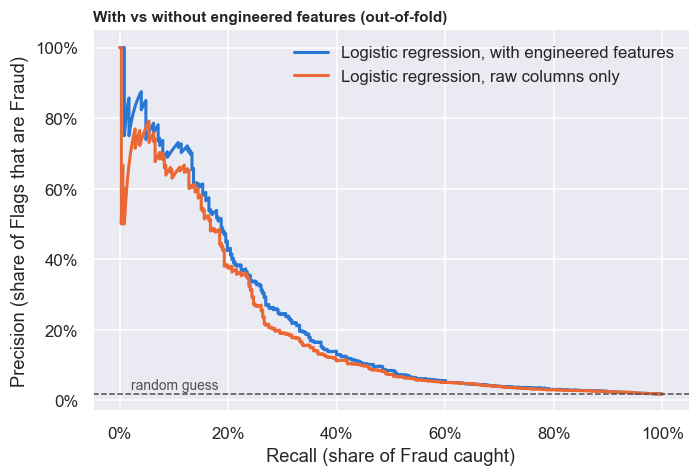

,PR-AUC,precision at 10% Recall,precision at 25% Recall,precision at 40% Recall
with engineered features,0.222,73.1%,33.6%,13.0%
raw columns only,0.199,66.7%,27.0%,11.4%


In [35]:
raw_only_scores = oof_first_repeat(lambda: with_preprocessing(LogisticRegression(max_iter=1000), NUMERIC_RAW))
feature_versions = {"with engineered features": oof_baseline, "raw columns only": raw_only_scores}
version_colors = {"with engineered features": "#2a78d6", "raw columns only": "#eb6834"}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, scores in feature_versions.items():
    p, r, _ = precision_recall_curve(y, scores)
    ax.plot(r, p, color=version_colors[name], linewidth=2, label=f"Logistic regression, {name}")
ax.axhline(fraud_rate, color=INK, linestyle="--", linewidth=1)
ax.text(0.02, fraud_rate + 0.015, "random guess", color=INK)
ax.set_xlabel("Recall (share of Fraud caught)")
ax.set_ylabel("Precision (share of Flags that are Fraud)")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(frameon=False)
ax.set_title("With vs without engineered features (out-of-fold)")
plt.show()

pd.DataFrame({name: {"PR-AUC": f"{average_precision_score(y, s):.3f}",
                     **{f"precision at {lvl:.0%} Recall": f"{best_precision(s, lvl):.1%}" for lvl in (0.10, 0.25, 0.40)}}
              for name, s in feature_versions.items()}).T

**Conclusion: the engineered features improve the model at almost every Recall level.** The curve with features sits above the raw-columns curve nearly everywhere:

- PR-AUC 0.222 against 0.199;
- precision at 25% Recall: 33.6% against 27.0%.

Across all 15 folds the raw-columns version never beats the version with features (6.2 table).

## 6.3 What the comparison tells us

- **The engineered features help.** Without them, logistic regression's PR-AUC drops from 0.228 to 0.207, and the raw-only version never beats it (0 of 15 folds). Section 4's features earn their place, and the curves above show the gain at almost every Recall level.
- **Class weights do not improve the ranking** (0.215, beating the baseline in 2 of 15 folds). They raise every Fraud Score, so 0.5 Flags far more Transactions, and they slightly worsen the ranking. At threshold 0.5 the weighted model reaches a Recall of 0.63, but by Flagging so many Transactions that F1 collapses to 0.09. Choosing the threshold deliberately (section 7) handles the rarity of Fraud without changing the model.
- **Tree models do not beat the linear model:** Gradient Boosting scores 0.203 and Random Forest 0.178, and they beat the baseline in at most 2 of 15 folds. If important *combinations* of features existed (e.g. new device *and* a large amount mattering more together than separately), trees would likely have found them. This supports the linear model's assumption that effects add up.
- **How big are these differences?** The gaps between the means (e.g. 0.228 against 0.203) are smaller than the spread across folds (about ± 0.04). The stronger evidence is the fold-by-fold count: logistic regression beats every candidate in at least 13 of the 15 folds.
- **SMOTE does not help here:** Gradient Boosting scores 0.198 with SMOTE against 0.203 without, so adding synthetic Frauds did not improve the ranking.

**Decision: the final model is the logistic regression baseline.** It ranks Fraud best on average, no candidate beats it in more than 2 of 15 folds, it is the simplest model, and every prediction can be explained with the odds multipliers from section 5.4. This follows the brief's own advice: better modelling is about the right model for the situation, not the most complicated one.

# 7. Evaluate performance

## 7.1 Choosing the Operating Threshold

The final model ranks Fraud well, but at the default threshold of 0.5 it Flags almost nothing (section 5.5). We now choose the threshold deliberately.

**How:**

1. Every training Transaction gets an **out-of-fold Fraud Score**: a score from a model that never saw it during training. The 3 repeats of our 5-fold cross-validation give 3 such scores per Transaction.
2. For each candidate threshold from 0.010 to 0.995, we compute F1 in each repeat and average over the repeats.
3. **Rule:** take the threshold with the best F1, then move **down** to the lowest threshold whose F1 is still within 0.01 of that best. A lower threshold Flags more Transactions, so it raises Recall while keeping F1 almost unchanged. All three metrics count, so we trade a little precision for that extra Recall (7.2 shows the cost).

In [36]:
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.005), 3)

def metric_by_threshold(metric, truth, score):
    """The metric (e.g. f1_score) at every candidate threshold."""
    return np.array([metric(truth, (score >= t).astype(int), zero_division=0) for t in THRESHOLDS])

def choose_threshold(truths, scores):
    """Lowest threshold, next to the best-F1 one, whose mean F1 is within 0.01 of the best."""
    mean_f1 = np.mean([metric_by_threshold(f1_score, t, s) for t, s in zip(truths, scores)], axis=0)
    best = i = int(mean_f1.argmax())
    while i > 0 and mean_f1[i - 1] >= mean_f1[best] - 0.01:
        i -= 1
    return THRESHOLDS[i], THRESHOLDS[best], mean_f1

# Out-of-fold Fraud Scores: one row per repeat, each Transaction scored by a model that never saw it.
oof_scores = np.zeros((N_REPEATS, len(y)))
for k, (train_idx, valid_idx) in enumerate(FOLDS):
    oof_scores[k // N_SPLITS, valid_idx] = logistic_regression().fit(X.iloc[train_idx], y.iloc[train_idx]).predict_proba(X.iloc[valid_idx])[:, 1]

OPERATING_THRESHOLD, best_f1_threshold, mean_f1 = choose_threshold([y] * N_REPEATS, list(oof_scores))
print(f"Best F1 {mean_f1.max():.3f} at threshold {best_f1_threshold}")
print(f"Chosen Operating Threshold: {OPERATING_THRESHOLD} (F1 {mean_f1[THRESHOLDS == OPERATING_THRESHOLD][0]:.3f})")

Best F1 0.292 at threshold 0.155
Chosen Operating Threshold: 0.12 (F1 0.287)


## 7.2 The trade-off: Recall against False Alarm

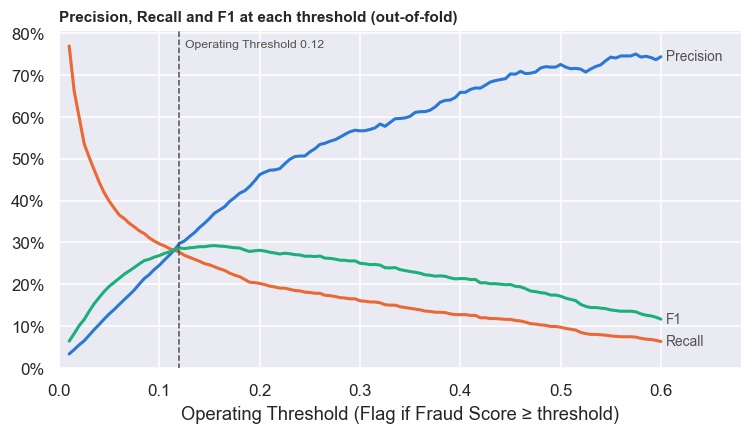

,Precision,Recall,F1
0.050,0.129,0.398,0.195
0.080,0.201,0.328,0.249
0.120,0.298,0.277,0.287
0.155,0.370,0.242,0.292
0.300,0.567,0.161,0.250
0.500,0.725,0.097,0.172


In [37]:
def mean_over_repeats(metric):
    return np.mean([metric_by_threshold(metric, y, s) for s in oof_scores], axis=0)

curves = {"Precision": mean_over_repeats(precision_score), "Recall": mean_over_repeats(recall_score), "F1": mean_f1}
colors = {"Precision": "#2a78d6", "Recall": "#eb6834", "F1": "#1baf7a"}

fig, ax = plt.subplots(figsize=(8, 4))
shown = THRESHOLDS <= 0.6   # above ~0.6 almost nothing is Flagged and the curves stop meaning anything
for name, values in curves.items():
    ax.plot(THRESHOLDS[shown], values[shown], color=colors[name], linewidth=2)
    ax.text(THRESHOLDS[shown][-1] + 0.005, values[shown][-1], name, color=INK, va="center")
ax.axvline(OPERATING_THRESHOLD, color=INK, linestyle="--", linewidth=1)
ax.text(OPERATING_THRESHOLD + 0.005, 0.95, f"Operating Threshold {OPERATING_THRESHOLD}", color=INK, fontsize=8,
        transform=ax.get_xaxis_transform())
ax.set_xlim(0, 0.68)
ax.set_xlabel("Operating Threshold (Flag if Fraud Score ≥ threshold)")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Precision, Recall and F1 at each threshold (out-of-fold)")
plt.show()

pd.DataFrame({name: values for name, values in curves.items()}, index=THRESHOLDS).loc[[0.05, 0.08, OPERATING_THRESHOLD, best_f1_threshold, 0.3, 0.5]].round(3)

Reading the trade-off:

- **At very low thresholds** the model Flags many Transactions. Recall rises, but most Flags are False Alarms, so precision and F1 collapse. This is the "disruption to legitimate customers" the brief warns about.
- **At high thresholds** almost every Flag is right, but most Fraud slips through.
- **The chosen threshold sits just below the F1 peak:** its F1 is within 0.01 of the best (0.287 vs 0.292). It catches more Fraud than the peak threshold (Recall 0.277 vs 0.242), at the cost of precision (0.298 vs 0.370). It balances catching Fraud against avoiding False Alarms.

## 7.3 Performance at the Operating Threshold

In [38]:
final_scores = score_folds(lambda k, train_idx, valid_idx: oof_scores[k // N_SPLITS, valid_idx], threshold=OPERATING_THRESHOLD)
display(summarise({f"Final model at {OPERATING_THRESHOLD}": final_scores},
                  metrics=("PR-AUC", "F1", "Recall", "Precision"), label="").T.rename(columns=lambda c: "mean ± sd over 15 folds"))

flagged = 1000 * final_scores["Flags"].mean() / (len(y) / N_SPLITS)
correct = flagged * final_scores["Precision"].mean()
print(f"Per 1,000 Transactions: about {1000 * fraud_rate:.0f} are Fraud; the model Flags about {flagged:.0f}, "
      f"of which about {correct:.0f} are real Fraud and {flagged - correct:.0f} are False Alarms.")

,mean ± sd over 15 folds
PR-AUC,0.228 ± 0.038
F1,0.287 ± 0.042
Recall,0.277 ± 0.041
Precision,0.300 ± 0.050


Per 1,000 Transactions: about 18 are Fraud; the model Flags about 16, of which about 5 are real Fraud and 11 are False Alarms.


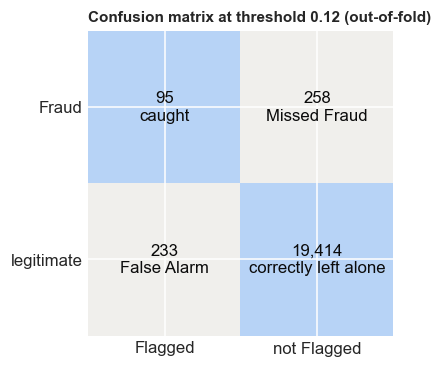

Fraud caught: 95 of 353 (26.9%) | False Alarms: 233 of 19,647 legitimate (1.2%) | Flags that are Fraud: 95 of 328 (29.0%)


model's decision,Flagged,not Flagged
truth,,
Fraud,95,258
legitimate,233,19414


In [39]:
from matplotlib.colors import ListedColormap
flags = (oof_scores[0] >= OPERATING_THRESHOLD).astype(int)   # first repeat: every Transaction scored once, out-of-fold
matrix = pd.crosstab(y.map({1: "Fraud", 0: "legitimate"}), pd.Series(flags, index=y.index).map({1: "Flagged", 0: "not Flagged"}))
matrix = matrix.loc[["Fraud", "legitimate"], ["Flagged", "not Flagged"]].rename_axis(index="truth", columns="model's decision")
labels = [["caught", "Missed Fraud"], ["False Alarm", "correctly left alone"]]

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.imshow([[1, 0], [0, 1]], cmap=ListedColormap(["#f0efec", "#b7d3f6"]))   # blue = correct decision, grey = mistake
for r in range(2):
    for c in range(2):
        ax.text(c, r, f"{matrix.iat[r, c]:,}\n{labels[r][c]}", ha="center", va="center", fontsize=11, color="#0b0b0b")
ax.set_xticks([0, 1], matrix.columns)
ax.set_yticks([0, 1], matrix.index)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title(f"Confusion matrix at threshold {OPERATING_THRESHOLD} (out-of-fold)")
plt.show()
caught, missed = matrix.loc["Fraud", "Flagged"], matrix.loc["Fraud", "not Flagged"]
alarms, left_alone = matrix.loc["legitimate", "Flagged"], matrix.loc["legitimate", "not Flagged"]
print(f"Fraud caught: {caught} of {caught + missed} ({caught / (caught + missed):.1%}) | "
      f"False Alarms: {alarms} of {alarms + left_alone:,} legitimate ({alarms / (alarms + left_alone):.1%}) | "
      f"Flags that are Fraud: {caught} of {caught + alarms} ({caught / (caught + alarms):.1%})")
matrix

**Conclusion: the model catches about a quarter of Fraud while Flagging very few legitimate Transactions.**

- **Fraud caught:** 95 of the 353 Frauds (26.9%). The other 258 are Missed Fraud.
- **False Alarms:** only 233 of the 19,647 legitimate Transactions are Flagged by mistake (1.2%).
- **Flags that are Fraud:** 95 of the 328 Flags (29.0%), about 3 in 10.

These counts come from one round of out-of-fold scores, so they match the cross-validated averages above closely but not exactly.

**What this means in practice**, for every 1,000 Transactions:

- about 18 are Fraud;
- the model Flags about 16;
- about 5 of those Flags are real Fraud, so **3 in 10 Flags are correct**;
- it catches **about 28% of all Fraud** (Recall);
- the other 11 Flags are False Alarms (legitimate Transactions).

Compare the default threshold of 0.5: Recall under 10%.

## 7.4 Honesty check: did choosing the threshold inflate the scores?

The threshold in 7.1 was chosen using the same out-of-fold scores that 7.3 evaluates, which can make the results look slightly better than they really are. To check, we repeat the whole procedure the strict way:

1. For each of the 15 folds, choose the threshold using **only that fold's training data** (with an inner 3-fold cross-validation).
2. Apply that threshold to the validation fold, which played no part in the choice.

In [40]:
strict_rows, strict_thresholds = [], []
for k, (train_idx, valid_idx) in enumerate(FOLDS):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    inner_scores = np.zeros(len(train_idx))
    for in_tr, in_va in StratifiedKFold(3, shuffle=True, random_state=k).split(X_tr, y_tr):
        inner_scores[in_va] = logistic_regression().fit(X_tr.iloc[in_tr], y_tr.iloc[in_tr]).predict_proba(X_tr.iloc[in_va])[:, 1]
    threshold, _, _ = choose_threshold([y_tr.to_numpy()], [inner_scores])
    strict_thresholds.append(threshold)
    strict_rows.append(fold_metrics(y.iloc[valid_idx], oof_scores[k // N_SPLITS, valid_idx], threshold))

strict = pd.DataFrame(strict_rows)
display(pd.DataFrame({"threshold chosen on the same data (7.3)": final_scores[["F1", "Recall", "Precision"]].mean(),
                      "threshold chosen strictly (7.4)": strict[["F1", "Recall", "Precision"]].mean()}).round(3))
print(f"Thresholds chosen strictly: from {min(strict_thresholds)} to {max(strict_thresholds)}")

,threshold chosen on the same data (7.3),threshold chosen strictly (7.4)
F1,0.287,0.288
Recall,0.277,0.259
Precision,0.300,0.331


Thresholds chosen strictly: from 0.12 to 0.195


**Conclusion: choosing the threshold on the same data barely inflated the results.** The thresholds chosen strictly, fold by fold, range from 0.12 to 0.195, yet F1 stays the same (0.288 vs 0.287). Recall is slightly lower (0.259 vs 0.277) and precision slightly higher (0.331 vs 0.300).

## 7.5 Which model is best at what?

Section 6 compared the models on PR-AUC, and on F1 and Recall at the default threshold of 0.5. That default is unfair: each model's scores sit differently around 0.5. For example, class weights inflate every score (6.3).

So here **every model gets its own Operating Threshold, chosen by the same rule as in 7.1** on its own out-of-fold scores. Then we ask, metric by metric, which model is best.

In [41]:
def oof_all_repeats(make_model):
    """Out-of-fold Fraud Scores for every repeat: one row per repeat, each Transaction scored by a model that never saw it."""
    scores = np.zeros((N_REPEATS, len(y)))
    for k, (train_idx, valid_idx) in enumerate(FOLDS):
        scores[k // N_SPLITS, valid_idx] = make_model().fit(X.iloc[train_idx], y.iloc[train_idx]).predict_proba(X.iloc[valid_idx])[:, 1]
    return scores

candidate_scores = {
    "Logistic regression": oof_scores,   # computed in 7.1
    "LR, raw columns only": oof_all_repeats(lambda: with_preprocessing(LogisticRegression(max_iter=1000), NUMERIC_RAW)),
    "LR, class weights": oof_all_repeats(lambda: with_preprocessing(LogisticRegression(max_iter=1000, class_weight="balanced"))),
    "Random Forest": oof_all_repeats(lambda: with_preprocessing(random_forest())),
    "Gradient Boosting": oof_all_repeats(lambda: with_preprocessing(gradient_boosting())),
    "Gradient Boosting + SMOTE": oof_all_repeats(gradient_boosting_smote),
}

fair_rows = {}
for name, scores in candidate_scores.items():
    threshold, _, _ = choose_threshold([y] * N_REPEATS, list(scores))
    per_fold = score_folds(lambda k, train_idx, valid_idx: scores[k // N_SPLITS, valid_idx], threshold=threshold)
    fair_rows[name] = {"own threshold": threshold, **per_fold[["PR-AUC", "F1", "Recall", "Precision"]].mean().round(3).to_dict()}
fair = pd.DataFrame(fair_rows).T.sort_values("F1", ascending=False)
display(fair)

for metric in ["PR-AUC", "F1", "Recall", "Precision"]:
    print(f"Best {metric:9s}: {fair[metric].idxmax()} ({fair[metric].max():.3f})")

,own threshold,PR-AUC,F1,Recall,Precision
Logistic regression,0.120,0.228,0.287,0.277,0.300
"LR, class weights",0.905,0.215,0.273,0.222,0.360
Gradient Boosting + SMOTE,0.205,0.198,0.270,0.224,0.348
"LR, raw columns only",0.115,0.207,0.266,0.247,0.290
Gradient Boosting,0.110,0.203,0.259,0.236,0.291
Random Forest,0.240,0.178,0.249,0.195,0.352


Best PR-AUC   : Logistic regression (0.228)
Best F1       : Logistic regression (0.287)
Best Recall   : Logistic regression (0.277)
Best Precision: LR, class weights (0.360)


**1. Best overall ranking (PR-AUC): logistic regression (0.228)**
It ranks Fraud above legitimate Transactions better than any other model, so whichever threshold is chosen, it has the best starting point.

**2. Best balance of catching Fraud and avoiding False Alarms (F1): logistic regression (0.287)**
At its own threshold it beats every alternative, including class weights (0.273) and Gradient Boosting + SMOTE (0.270).

**3. Most Fraud caught (Recall): logistic regression (0.277)**
It catches more Fraud than any other model at its chosen threshold.

**4. Most precise Flags (precision): logistic regression with class weights (0.360)**
When it Flags a Transaction it is right 36% of the time, but it catches less Fraud (Recall 0.222) and ranks worse (PR-AUC 0.215). Its precision comes from Flagging less at a very high threshold, not from ranking better. Random Forest (0.352) and Gradient Boosting + SMOTE (0.348) follow the same pattern.

**Recommendation: logistic regression.** Once every model is given a fair threshold, logistic regression is best on all three scored metrics (PR-AUC, F1 and Recall), and it is also the simplest and most explainable model. This confirms the choice made on PR-AUC alone in section 6.

Class weights look very different here than at 0.5: with a fair threshold (0.905, high because class weights inflate every score) its F1 rises from 0.09 to 0.273. That is still below logistic regression without weights. This is the danger of comparing models at the default threshold.

## 7.6 Tuning the final model for PR-AUC

The leaderboard scores **PR-AUC on the Fraud Scores**, so the final model is tuned for ranking. On the same 15 folds, two changes to the logistic regression improved PR-AUC:

- **Stronger regularisation** (`C=0.1` instead of 1), which steadies the coefficients of the overlapping features;
- **five extra features**, added to `make_features`: log average spend per Transaction, amount relative to that average, share of the 24-hour Transactions made in the last hour, new device × log amount, and new device × young Account (under 230 days).

Splines, pairwise interactions, tuned Gradient Boosting, Extra Trees, LightGBM (best 0.226) and blends of logistic regression with tree models did not beat this model reliably: the best blend gained under 0.003 and won only about half the folds. The Operating Threshold for `predict()` is re-chosen for it with the rule from 7.1.

In [42]:
EXTRA_FEATURES = ["avg_spend_per_txn", "amount_vs_avg_txn", "share_last_1h", "newdev_x_logamt", "young_x_newdev"]
FINAL_FEATURES = NUMERIC_FEATURES + EXTRA_FEATURES + CATEGORICAL
X_final = make_features(train)[FINAL_FEATURES]

def final_logistic_regression():
    return Pipeline([("prep", build_preprocessor(NUMERIC_FEATURES + EXTRA_FEATURES)),
                     ("model", LogisticRegression(C=0.1, max_iter=2000))])

final_oof = np.zeros((N_REPEATS, len(y)))
final_pr_auc = []
for k, (train_idx, valid_idx) in enumerate(FOLDS):
    scores = final_logistic_regression().fit(X_final.iloc[train_idx], y.iloc[train_idx]).predict_proba(X_final.iloc[valid_idx])[:, 1]
    final_oof[k // N_SPLITS, valid_idx] = scores
    final_pr_auc.append(average_precision_score(y.iloc[valid_idx], scores))
final_pr_auc = np.array(final_pr_auc)
baseline_pr_auc = results["Logistic regression"]["PR-AUC"].to_numpy()
print(f"PR-AUC: {final_pr_auc.mean():.4f} ± {final_pr_auc.std():.4f} (baseline logistic regression {baseline_pr_auc.mean():.4f}); "
      f"better in {(final_pr_auc > baseline_pr_auc).sum()} of {len(FOLDS)} folds")

FINAL_THRESHOLD, _, _ = choose_threshold([y.to_numpy()] * N_REPEATS, list(final_oof))
print("Operating Threshold for the final model:", FINAL_THRESHOLD)

PR-AUC: 0.2361 ± 0.0371 (baseline logistic regression 0.2281); better in 12 of 15 folds


Operating Threshold for the final model: 0.11


## 7.7 Final model and `model.pkl`

The final model is the tuned logistic regression pipeline from 7.6, retrained on **all** 20,000 training Transactions, with the Operating Threshold built in. scikit-learn's `FixedThresholdClassifier` makes `predict()` return Flags (0/1) at that threshold, while `predict_proba()` still returns the Fraud Scores. The file is saved with `joblib` and stores `(model, FINAL_FEATURES)`, exactly what the platform's prediction template loads, and contains only standard scikit-learn objects.

In [43]:
import joblib

final_model = FixedThresholdClassifier(final_logistic_regression(), threshold=FINAL_THRESHOLD,
                                       response_method="predict_proba")
final_model.fit(X_final, y)

MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump((final_model, FINAL_FEATURES), MODEL_PATH)
print("Saved model.pkl with", len(FINAL_FEATURES), "feature names; Operating Threshold", FINAL_THRESHOLD)

Saved model.pkl with 21 feature names; Operating Threshold 0.11


## 7.8 Checking the saved model the way the platform will use it

The platform runs the prediction template: it loads `model.pkl` with `joblib`, applies `make_features` to a test file that has **no `id` column and shuffled rows**, and writes one Fraud Score per row under `prediction`. We repeat that here on the Public Test Set, check the scores do not depend on the `id` column or the row order, and save `outputs/test_predictions.csv` (`id`, Fraud Score and Flag).

In [44]:
loaded_model, loaded_features = joblib.load(MODEL_PATH)

# As on the platform: no id column, rows shuffled.
platform_test = test.drop(columns="id").sample(frac=1, random_state=0)
platform_scores = loaded_model.predict_proba(make_features(platform_test)[loaded_features])[:, 1]

fraud_scores = loaded_model.predict_proba(make_features(test)[loaded_features])[:, 1]
same = np.allclose(platform_scores, fraud_scores[platform_test.index.to_numpy()])
print(f"Scores identical without the id column and with shuffled rows: {same}")
print(f"Fraud Scores: {len(fraud_scores)} rows, from {fraud_scores.min():.4f} to {fraud_scores.max():.4f}")
print(f"Flagged at the Operating Threshold: {loaded_model.predict(make_features(test)[loaded_features]).mean():.2%} of the Public Test Set "
      f"(training data: {loaded_model.predict(X_final).mean():.2%})")

# Predictions for the Public Test Set, in its row order: id, Fraud Score and Flag.
predictions = pd.DataFrame({"id": test["id"], "fraud_score": fraud_scores,
                            "flag": loaded_model.predict(make_features(test)[loaded_features])})
PREDICTIONS_PATH.parent.mkdir(exist_ok=True)
predictions.to_csv(PREDICTIONS_PATH, index=False)
print(f"Saved {PREDICTIONS_PATH.relative_to(ROOT)}:", predictions.shape[0], "rows x", predictions.shape[1], "columns:", list(predictions.columns))

# The training-range caps in make_features: an extreme amount is scored like the largest amount seen in training.
extreme = test.iloc[[0, 0]].copy()
extreme["transaction_amount"] = [9000, 10_000_000]
print("Fraud Score at amount 9,000 vs 10,000,000:",
      loaded_model.predict_proba(make_features(extreme)[loaded_features])[:, 1].round(4))

Scores identical without the id column and with shuffled rows: True
Fraud Scores: 12000 rows, from 0.0012 to 0.8858
Flagged at the Operating Threshold: 2.82% of the Public Test Set (training data: 1.68%)


Saved outputs/test_predictions.csv: 12000 rows x 3 columns: ['id', 'fraud_score', 'flag']
Fraud Score at amount 9,000 vs 10,000,000: [0.0357 0.0357]


The model Flags a larger share of the Public Test Set than of the training data. This is consistent with section 2.9: the Public Test Set contains more new devices and larger amounts, both of which raise the Fraud Score (odds ×1.55 and ×1.50, section 5.4). The model is applying the same rules to riskier-looking data.

# 8. Is the final model trustworthy?

A good PR-AUC is not enough on its own. This section checks the final model (section 7.6) four ways:

1. **Overfitting and underfitting:** does it do as well on unseen data as on the data it learned from?
2. **Calibration:** when it gives a Fraud Score of 10%, are about 10% of those Transactions really Fraud?
3. **Bias across groups:** does it catch Fraud and raise False Alarms at similar rates for every country and channel?
4. **Usefulness:** how much Fraud is caught by reviewing only the highest-scored Transactions?

All four use out-of-fold Fraud Scores, so every Transaction is scored by a model that never saw it.

## 8.1 Learning curve: overfitting or underfitting?

Each model is trained on a growing share of the training folds (first repeat, 5 folds) and scored on the data it learned from and on the validation fold. **Overfitting** shows as a training line far above the validation line; **underfitting** shows as both lines low and flat from the start.

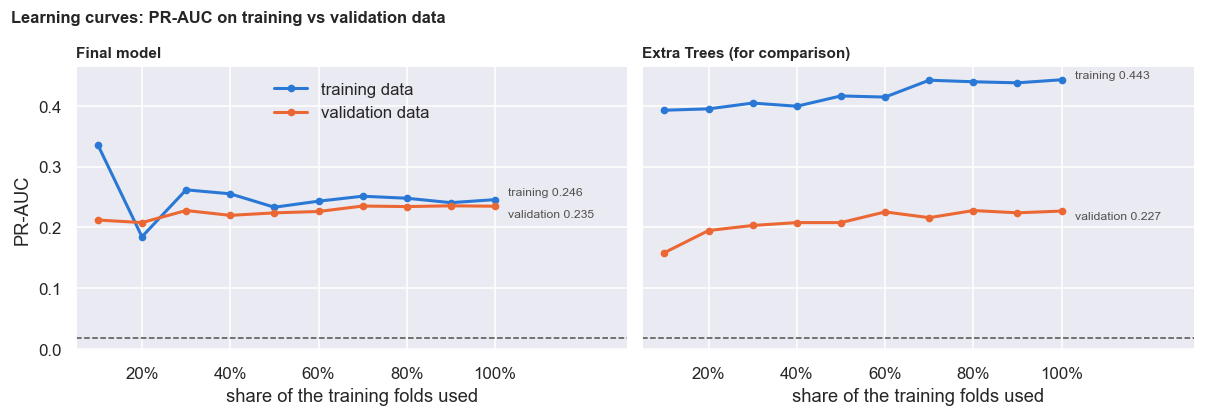

,Final model (training),Final model (validation),Extra Trees (for comparison) (training),Extra Trees (for comparison) (validation)
10%,0.336,0.212,0.393,0.159
50%,0.233,0.224,0.416,0.208
100%,0.246,0.235,0.443,0.227


In [45]:
rng = np.random.default_rng(42)
shares = np.round(np.arange(0.1, 1.01, 0.1), 1)
curve = {"Final model": ([], []), "Extra Trees (for comparison)": ([], [])}

def extra_trees():
    return Pipeline([("prep", build_preprocessor(NUMERIC_FEATURES + EXTRA_FEATURES)),
                     ("model", ExtraTreesClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.5,
                                                    n_jobs=-1, random_state=42))])

for share in shares:
    rows = {name: [] for name in curve}
    for train_idx, valid_idx in FOLDS[:N_SPLITS]:
        sub = train_idx if share == 1 else rng.choice(train_idx, int(len(train_idx) * share), replace=False)
        for name, make in [("Final model", final_logistic_regression), ("Extra Trees (for comparison)", extra_trees)]:
            m = make().fit(X_final.iloc[sub], y.iloc[sub])
            rows[name].append([average_precision_score(y.iloc[idx], m.predict_proba(X_final.iloc[idx])[:, 1])
                               for idx in (sub, valid_idx)])
    for name in curve:
        train_score, valid_score = np.mean(rows[name], axis=0)
        curve[name][0].append(train_score); curve[name][1].append(valid_score)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, (train_line, valid_line)) in zip(axes, curve.items()):
    ax.plot(shares, train_line, color=HIGHLIGHT, linewidth=2, marker="o", markersize=4)
    ax.plot(shares, valid_line, color="#eb6834", linewidth=2, marker="o", markersize=4)
    gap = max(0.02 - abs(train_line[-1] - valid_line[-1]), 0) / 2     # keep the two end labels apart
    ax.text(1.03, train_line[-1] + gap, f"training {train_line[-1]:.3f}", color=INK, va="bottom", fontsize=8)
    ax.text(1.03, valid_line[-1] - gap, f"validation {valid_line[-1]:.3f}", color=INK, va="top", fontsize=8)
    ax.axhline(fraud_rate, color=INK, linestyle="--", linewidth=1)
    ax.set_xlim(0.05, 1.3)
    ax.set_xticks(np.arange(0.2, 1.01, 0.2))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("share of the training folds used")
    ax.set_title(name)
axes[0].set_ylabel("PR-AUC")
axes[0].legend(["training data", "validation data"], frameon=False, loc="upper center")
fig.suptitle("Learning curves: PR-AUC on training vs validation data", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

pd.DataFrame({f"{name} ({kind})": line for name, (t, v) in curve.items() for kind, line in [("training", t), ("validation", v)]},
             index=[f"{s:.0%}" for s in shares]).round(3).iloc[[0, 4, 9]]

**Conclusion: the final model neither overfits nor underfits.**

- **No overfitting:** with all the training data, its PR-AUC is 0.246 on the data it learned from and 0.235 on unseen data. The lines meet; a gap of 0.011 is small.
- **No underfitting by the model:** a far more flexible model (Extra Trees) scores 0.443 on its training data but only 0.227 on unseen data. Extra flexibility memorises noise instead of finding more Fraud.
- **The ceiling comes from the data:** the validation line is flat from about half the data onwards, so more Transactions of the same kind would add little. Better Fraud detection needs new information (for example, Account history), not a bigger model.

## 8.2 Calibration: can the Fraud Scores be read as probabilities?

Transactions are grouped into ten equal-sized groups by Fraud Score. For each group, the average Fraud Score (predicted) is plotted against the share that really were Fraud (observed). A well-calibrated model sits on the diagonal.

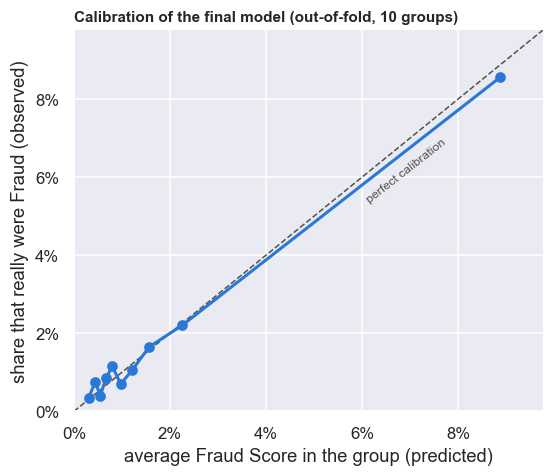

,0,1,2,3,4,5,6,7,8,9
predicted,0.31%,0.44%,0.55%,0.66%,0.80%,0.97%,1.21%,1.57%,2.25%,8.87%
observed,0.35%,0.75%,0.40%,0.85%,1.15%,0.70%,1.05%,1.65%,2.20%,8.55%


In [46]:
from sklearn.calibration import calibration_curve
oof_final = final_oof[0]   # first repeat: every Transaction scored once, out-of-fold
observed, predicted = calibration_curve(y, oof_final, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
top = max(observed.max(), predicted.max()) * 1.1
ax.plot([0, top], [0, top], color=INK, linestyle="--", linewidth=1)
ax.text(top * 0.62, top * 0.55, "perfect calibration", color=INK, fontsize=8, rotation=38)
ax.plot(predicted, observed, color=HIGHLIGHT, linewidth=2, marker="o", markersize=6)
ax.set_xlim(0, top); ax.set_ylim(0, top)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("average Fraud Score in the group (predicted)")
ax.set_ylabel("share that really were Fraud (observed)")
ax.set_title("Calibration of the final model (out-of-fold, 10 groups)")
plt.show()
pd.DataFrame({"predicted": predicted, "observed": observed}).map("{:.2%}".format).T

**Conclusion: the Fraud Scores can be read as probabilities.** The points sit close to the diagonal. In the highest-scored tenth, the average score is 8.9% and 8.6% really were Fraud; in the lower groups the differences are under half a percentage point, which is within the noise of about 20 Frauds per group.

## 8.3 Bias check: is any group treated differently?

At the Operating Threshold, we compare two rates for each country and each channel:

- **Fraud caught (Recall):** of that group's Fraud, what share is Flagged?
- **False Alarm rate:** of that group's legitimate Transactions, what share is Flagged by mistake?

The dashed line is the overall rate. Each label shows how many Frauds the group contains; with only a few Frauds, a group's Recall is very uncertain.

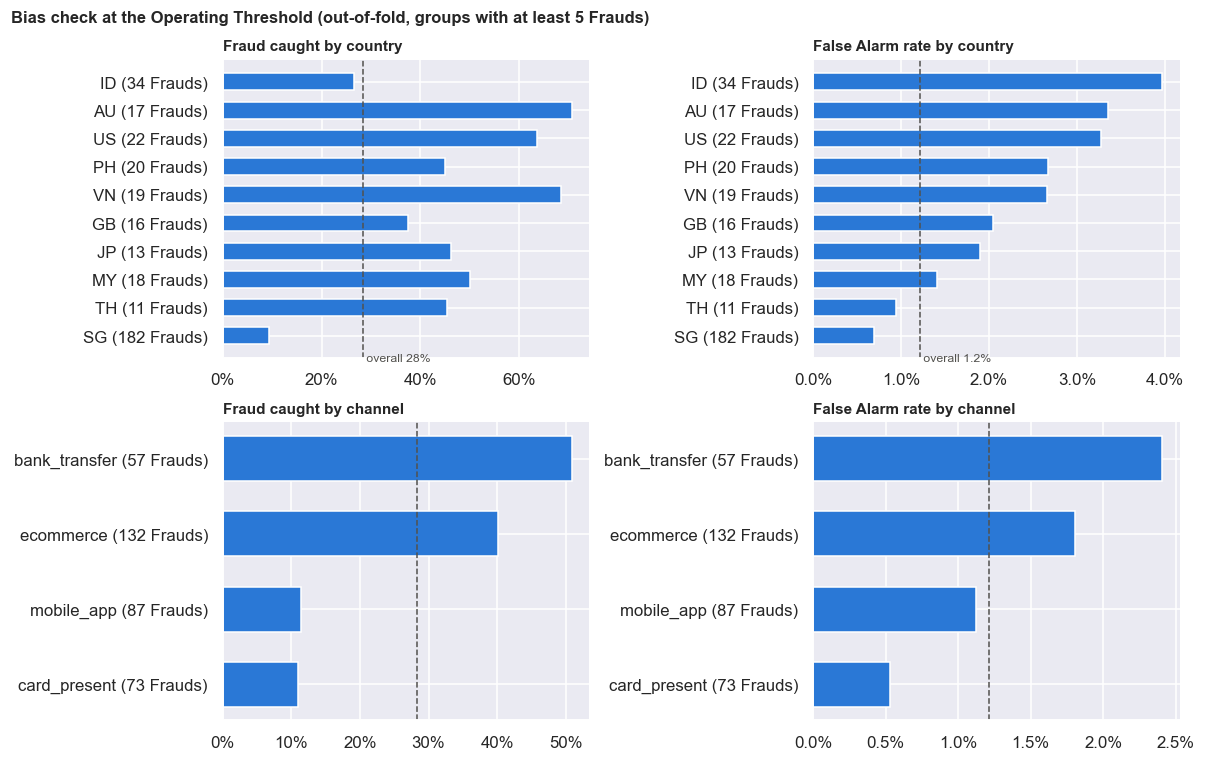

Frauds Fraud caught False Alarm rate
dimension                                                    
country   SG                182         9.3%            0.70%
          TH                 11        45.5%            0.95%
          MY                 18        50.0%            1.41%
          JP                 13        46.2%            1.90%
          GB                 16        37.5%            2.04%
          VN                 19        68.4%            2.66%
          PH                 20        45.0%            2.67%
          US                 22        63.6%            3.28%
          AU                 17        70.6%            3.35%
          ID                 34        26.5%            3.97%
channel   card_present       73        11.0%            0.53%
          mobile_app         87        11.5%            1.12%
          ecommerce         132        40.2%            1.80%
          bank_transfer      57        50.9%            2.41%

In [47]:
flags = (oof_final >= FINAL_THRESHOLD).astype(int)
group_frame = pd.DataFrame({"fraud": y.to_numpy(), "flag": flags,
                            "country": X_final["country"].fillna("(missing)").to_numpy(),
                            "channel": X_final["transaction_channel"].fillna("(missing)").to_numpy()})

def group_rates(col):
    g = group_frame.groupby(col)
    out = pd.DataFrame({"Frauds": g["fraud"].sum(),
                        "Fraud caught": g.apply(lambda d: d.loc[d.fraud == 1, "flag"].mean(), include_groups=False),
                        "False Alarm rate": g.apply(lambda d: d.loc[d.fraud == 0, "flag"].mean(), include_groups=False)})
    return out[out["Frauds"] >= 5].sort_values("False Alarm rate")

overall_recall = group_frame.loc[group_frame.fraud == 1, "flag"].mean()
overall_false_alarm = group_frame.loc[group_frame.fraud == 0, "flag"].mean()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
bias_tables = {}
for row, (col, label) in enumerate([("country", "country"), ("channel", "channel")]):
    rates = group_rates(col); bias_tables[label] = rates
    names = [f"{i} ({int(n)} Frauds)" for i, n in zip(rates.index, rates["Frauds"])]
    for ax, metric, overall in [(axes[row, 0], "Fraud caught", overall_recall), (axes[row, 1], "False Alarm rate", overall_false_alarm)]:
        ax.barh(names, rates[metric], color=HIGHLIGHT, height=0.6)
        ax.axvline(overall, color=INK, linestyle="--", linewidth=1)
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0 if metric == "Fraud caught" else 1))
        ax.set_title(f"{metric} by {label}")
axes[0, 0].text(overall_recall, -0.9, f" overall {overall_recall:.0%}", color=INK, fontsize=8)
axes[0, 1].text(overall_false_alarm, -0.9, f" overall {overall_false_alarm:.1%}", color=INK, fontsize=8)
fig.suptitle("Bias check at the Operating Threshold (out-of-fold, groups with at least 5 Frauds)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
bias_table = pd.concat(bias_tables, names=["dimension"])
bias_table.assign(**{"Frauds": bias_table["Frauds"].astype(int),
                     "Fraud caught": bias_table["Fraud caught"].map("{:.1%}".format),
                     "False Alarm rate": bias_table["False Alarm rate"].map("{:.2%}".format)})

**Does removing the `country` column remove the gap?** We retrain the same model without `country` (same folds, same threshold rule) and compare.

In [48]:
CATEGORICAL_NO_COUNTRY = ["merchant_category", "transaction_channel"]

def model_without_country():
    numeric = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(drop=[REFERENCE[CATEGORICAL.index(c)] for c in CATEGORICAL_NO_COUNTRY],
                                                     handle_unknown="ignore", sparse_output=False))])
    prep = ColumnTransformer([("numeric", numeric, NUMERIC_FEATURES + EXTRA_FEATURES), ("categorical", categorical, CATEGORICAL_NO_COUNTRY)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(C=0.1, max_iter=2000))])

no_country_oof = np.zeros((N_REPEATS, len(y)))
no_country_pr_auc = []
for k, (train_idx, valid_idx) in enumerate(FOLDS):
    scores = model_without_country().fit(X_final.iloc[train_idx], y.iloc[train_idx]).predict_proba(X_final.iloc[valid_idx])[:, 1]
    no_country_oof[k // N_SPLITS, valid_idx] = scores
    no_country_pr_auc.append(average_precision_score(y.iloc[valid_idx], scores))
no_country_threshold, _, _ = choose_threshold([y.to_numpy()] * N_REPEATS, list(no_country_oof))

def country_gap(scores, threshold):
    d = group_frame.assign(flag=(scores >= threshold).astype(int))
    big = d.groupby("country")["fraud"].sum() >= 5
    caught = d[d.fraud == 1].groupby("country")["flag"].mean()[big]
    false_alarm = d[d.fraud == 0].groupby("country")["flag"].mean()[big]
    return {"Fraud caught in SG": f"{caught['SG']:.1%}",
            "Fraud caught, other countries": f"{caught.drop('SG').min():.0%} to {caught.drop('SG').max():.0%}",
            "False Alarm rate range": f"{false_alarm.min():.2%} to {false_alarm.max():.2%}",
            "highest / lowest False Alarm rate": f"{false_alarm.max() / false_alarm.min():.1f}x"}

pd.DataFrame({f"with country (PR-AUC {final_pr_auc.mean():.4f})": country_gap(oof_final, FINAL_THRESHOLD),
              f"without country (PR-AUC {np.mean(no_country_pr_auc):.4f})": country_gap(no_country_oof[0], no_country_threshold)})

,with country (PR-AUC 0.2361),without country (PR-AUC 0.2354)
Fraud caught in SG,9.3%,9.3%
"Fraud caught, other countries",26% to 71%,24% to 71%
False Alarm rate range,0.70% to 3.97%,0.68% to 3.43%
highest / lowest False Alarm rate,5.7x,5.1x


**Conclusion: the model treats groups differently, and the reason is the data, not the `country` label.**

- **Countries:** Fraud in SG is caught only 9% of the time, against 26-71% elsewhere. False Alarms range from 0.70% (SG) to 3.97% (ID), about 6× apart. SG holds 182 of the 353 Frauds, and its Fraud looks much more like ordinary SG spending.
- **Channels:** card-present and mobile-app Fraud is caught about 11% of the time, against 40-51% for e-commerce and bank transfers.
- **Removing `country` barely changes this:** SG Fraud caught stays at 9.3%, and the False Alarm gap only narrows from about 5.7× to 5.1×, at almost no cost in PR-AUC. The differences come from how Transactions in each group look (amounts, channels, devices), not from the country itself.
- **What we would do in production:** set a separate Operating Threshold per group so False Alarm rates are equal, or collect features that separate SG Fraud better. Both need a business decision on which kind of fairness matters (equal False Alarms or equal Fraud caught). The submitted Fraud Scores (ranking) are unaffected by that choice.

## 8.4 Usefulness: how much Fraud does a small review catch?

If an analyst reviews Transactions from the highest Fraud Score down, how much of all Fraud is caught for each share of Transactions reviewed? A model with no skill catches Fraud in proportion to the share reviewed (the diagonal).

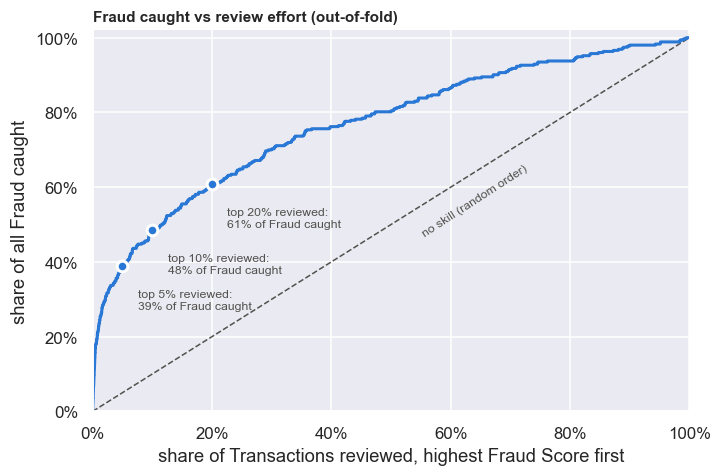

top 1%     22.7% of Fraud (22.7x random)
top 5%      38.8% of Fraud (7.8x random)
top 10%     48.4% of Fraud (4.8x random)
top 20%     60.9% of Fraud (3.0x random)
Name: Fraud caught, dtype: object

In [49]:
order = np.argsort(-oof_final)
caught = np.cumsum(y.to_numpy()[order]) / y.sum()
reviewed = np.arange(1, len(y) + 1) / len(y)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot([0, 1], [0, 1], color=INK, linestyle="--", linewidth=1)
ax.text(0.55, 0.47, "no skill (random order)", color=INK, fontsize=8, rotation=33)
ax.plot(reviewed, caught, color=HIGHLIGHT, linewidth=2)
for share in (0.05, 0.10, 0.20):
    k = int(share * len(y)) - 1
    ax.plot(reviewed[k], caught[k], "o", color=HIGHLIGHT, markersize=7, markeredgecolor="white", markeredgewidth=2)
    ax.annotate(f"top {share:.0%} reviewed:\n{caught[k]:.0%} of Fraud caught", (reviewed[k], caught[k]),
                xytext=(10, -28), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("share of Transactions reviewed, highest Fraud Score first")
ax.set_ylabel("share of all Fraud caught")
ax.set_title("Fraud caught vs review effort (out-of-fold)")
plt.show()
pd.Series({f"top {s:.0%}": f"{caught[int(s * len(y)) - 1]:.1%} of Fraud ({caught[int(s * len(y)) - 1] / s:.1f}x random)"
           for s in (0.01, 0.05, 0.10, 0.20)}, name="Fraud caught")

**Conclusion: a small review catches a large share of Fraud.** Reviewing the top 1% of Transactions by Fraud Score catches 22.7% of all Fraud (22.7× random). The top 5% catches 38.8%, the top 10% 48.4% and the top 20% 60.9%. A fraud team can choose its review budget from this curve.

# 9. Summary

**Problem.** Flag rare Fraud (1.8% of Transactions) while raising few False Alarms, scored on PR-AUC, F1 and Recall.

**Approach, in one line per step:**

1. Accuracy is misleading, so we focus on PR-AUC, F1 and Recall.
2. Exploration found strong single signals (new devices, cash transfers, luxury, certain countries, late night, large amounts, young Accounts) and a shifted Public Test Set.
3. Missing values are filled from training data only, with no "was missing" flags. Fixed cleaning rules guard against bad or extreme values in the Private Test Set.
4. Five engineered features (log amount, amount relative to recent spend, log account age, cyclical hour, night flag) improve the baseline.
5. **Logistic regression** beats a one-line rule in all 15 folds.
6. No more complex model (Random Forest, Gradient Boosting, Gradient Boosting + SMOTE, class weights) ranks Fraud better, so we keep the simplest.
7. A deliberately chosen Operating Threshold of 0.12 turns a good ranking into useful Flags.

**Logistic regression, cross-validated:** PR-AUC 0.228 (13× random), F1 0.287, Recall 0.277, precision 0.30.

**Final model (tuned for PR-AUC, section 7.6):** logistic regression with `C=0.1` and five extra features, PR-AUC 0.236, better than the baseline in 12 of 15 folds. `outputs/test_predictions.csv` holds its Fraud Scores.

**Trust checks (section 8):**

- **No overfitting or underfitting:** training and validation PR-AUC meet (0.246 vs 0.235).
- **Calibrated:** Fraud Scores match observed Fraud rates closely.
- **Bias found and explained:** Fraud in SG and in card-present / mobile-app Transactions is caught far less often, and False Alarm rates differ about 6× across countries. Removing `country` does not fix it; per-group thresholds would.
- **Useful:** the top 5% of scores holds 38.8% of all Fraud.

**Model assumptions:**

- effects are linear in the log-odds and add up;
- features overlap somewhat (e.g. amount and log amount), so single coefficients are read with care;
- Transactions are independent;
- the Private Test Set resembles the training data.

**Limitations and what we would do next:**

- **Some data columns look synthetic or inconsistent** (the 1-hour count, section 2.8).
- **The Public Test Set is shifted** towards larger amounts and new devices. If Fraud is also more common there, a slightly higher threshold could be better, but we cannot verify that without labels.
- **The night hours were chosen after looking at the data**, a small optimism (section 4.1).
- **The Operating Threshold was chosen on the same out-of-fold scores it is evaluated on.** The strict check in 7.4 shows this barely matters (F1 0.288 vs 0.287), but Recall is slightly lower (0.259 vs 0.277) when the threshold is chosen strictly.
- **Recall of about 28% leaves most Fraud uncaught.** That is the price of keeping False Alarms low. With real cost figures for a missed Fraud versus a False Alarm, the threshold should be set from those costs instead of F1.

# 10. Scoring new data

The saved model and `make_features` are packaged in `src/fraud_detection`. To score any CSV with the raw transaction columns:

```bash
PYTHONPATH=src python -m fraud_detection.predict data/test.csv outputs/test_predictions.csv
```

`notebooks/predict.ipynb` does the same in a notebook (it is the scoring notebook submitted to the competition platform).
